<div style="background:#174384;color:#fff;padding:22px 26px;border-left:12px solid #fcd12a;border-radius:4px">
<div style="font-size:26px;font-weight:700;color:#fcd12a">EDA Universal NLP</div>
<div style="font-size:15px;margin-top:6px">Setiap hasil EDA menjadi alasan keputusan modeling, bukan sekadar grafik.</div>
</div>

**Cara pakai**

1. Ubah sel **Konfigurasi**. Kolom yang tidak ada cukup diisi `None`: modulnya otomatis dilewati, tanpa error.
2. Jalankan dari atas ke bawah. Di data 500 ribu baris, langkah mahal otomatis memakai sampel.
3. Tiap modul mengeluarkan **tabel kondisi**: semua kemungkinan ditampilkan, dan baris <span style="background:#fcd12a;color:#174384;padding:0 5px"><b>kuning</b></span> adalah kondisi data saat ini. Kalau datanya beda, baris lain yang menyala dan kamu tetap tahu artinya.
4. Baca **Laporan Keputusan** di akhir: daftar temuan, jawaban pertanyaan juri, dan eksperimen berikutnya. Hasilnya tersimpan di `eda_out/`.

**Empat hal di tiap temuan:** apa yang ditemukan, artinya, aksinya, dan cara mengujinya.

> EDA menghasilkan hipotesis, validasi menghasilkan bukti. Batas angka di tabel adalah aturan praktis, jadi bisa diubah di sel *Buku aturan*. Hasil demo memakai data MBG publik yang labelnya sebagian besar buatan mesin.

| Lapis | Modul | Level data |
|---|---|---|
| **A. Dataset** | 01 Struktur · 02 Kualitas · 03 Sumber · 04 Panjang · 05 Waktu | Seluruh baris |
| **B. Bahasa** | 06 Bahasa · 07 Noise · 08 Kosakata · 09 Kata fungsi · 10 Struktur kalimat · 11 Semantik · 12 Entitas & angka | Sampel `N_LING` dan `N_SEM` |
| **C. Modeling** | 13 Duplikat · 14 Pasangan · 15 Label · 16 Shift · 17 Ablation & error · 18 Komputasi | Campuran |
| **D. Kondisional** | 19 Outlier · 20 Span · 21 Relasi aspek | Bila datanya mendukung |

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">Konfigurasi</h2>


In [1]:
from pathlib import Path
import os

# Sumber data. TRAIN=None memakai demo MBG dari bundle.
TRAIN, TEST = None, None  # "train.csv", "test.csv"
TEXT = "text"  # wajib
TEXT_B = None  # teks kedua untuk task pasangan
TARGET = "label"  # None, satu kolom, atau list untuk multilabel
TIME, SOURCE, ID = "time", "source", "id"
GROUP, PARENT, ENGAGE = "group", "parent_id", "likes"  # grup/video, id induk, likes
TAGS = None  # kolom BIO dipisah spasi, untuk NER
LABEL_DROP = ["empty"]  # nilai label yang berarti tidak berlabel

# Kamus domain. Ganti kalau temanya bukan MBG.
DOMAIN = {
    "keamanan_pangan": "keracunan|racun|basi|busuk|berjamur|belatung|ulat|mual|muntah|diare|klb",
    "kualitas_menu": "menu|ayam|nasi|sayur|susu|burger|roti|telur|telor|tempe|ikan|lauk|porsi|enak",
    "gizi": "gizi|bergizi|stunting|protein|kalori|sehat|nutrisi",
    "anggaran": "anggaran|apbn|pajak|triliun|dana|pemborosan|uang rakyat",
    "korupsi": "korupsi|koruptor|markup|tersangka|kejagung|calo|yayasan|proyek",
    "dapur_distribusi": "sppg|dapur|distribusi|terlambat|telat|relawan|mitra|merata",
    "pendidikan": "guru|honorer|murid|siswa|sekolah|kantin|santri",
    "penolakan": "stop|setop|hentikan|bubarkan|batalkan|tolak|menolak",
    "dukungan": "bagus|setuju|mendukung|dukung|bermanfaat|alhamdulillah|lanjutkan",
}

# Model bundle. Folder yang tidak ada otomatis memakai cadangan tanpa model.
ROOT = next(
    (
        p
        for p in map(Path, (os.environ.get("COMP_ROOT", "-"), r"C:\gemastik", r"D:\comp\bundle"))
        if (p / "models").exists()
    ),
    Path("-"),
)
MODELS = ROOT / "models"
EMB, NER, TOKENIZER = "e5-small", "nusabert-ner", "indobertweet"

# Ukuran sampel per level analisis
N_TARGET, N_LING, N_SEM, N_ABL, N_NER, N_MODEL, SEED = 500_000, 30_000, 5_000, 15_000, 800, 600, 42

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">Alat bantu</h2>


In [2]:
import json, re, time, warnings
from collections import Counter
import matplotlib.pyplot as plt, numpy as np, pandas as pd, seaborn as sns
from IPython.display import HTML, display
from matplotlib.colors import LinearSegmentedColormap as LSC

warnings.filterwarnings("ignore")
os.environ.update(
    HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1", TOKENIZERS_PARALLELISM="false", TQDM_DISABLE="1"
)
OUT = Path("eda_out")
OUT.mkdir(exist_ok=True)

NAVY, GOLD, SOFT = "#174384", "#fcd12a", "#e8edf5"
TINT = [NAVY, GOLD, "#7f9bc4", "#fde88f", "#b9c9e0", "#0e2a52"]
SEQ = LSC.from_list("seq", ["#ffffff", NAVY])
plt.rcParams.update(
    {
        "figure.dpi": 80,
        "figure.figsize": (9, 3.2),
        "axes.prop_cycle": plt.cycler(color=TINT),
        "axes.titleweight": "bold",
        "axes.titlecolor": NAVY,
        "axes.edgecolor": NAVY,
        "axes.labelcolor": NAVY,
        "xtick.color": NAVY,
        "ytick.color": NAVY,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

WORD = re.compile(r"[a-zà-ÿ]+")
EMOJI = "[\U0001f300-\U0001faff\u2600-\u27bf]"
toks = lambda x: WORD.findall(str(x).lower())
norm = lambda x: " ".join(toks(x))
pct = lambda m: round(100 * float(np.mean(m)), 2) if len(m) else 0.0
jac = lambda a, b: len(a & b) / max(1, len(a | b))
PII = re.compile(r"(?:\+?62|\b0)8\d{7,}|@[\w.]+|\S+@\S+\.\S+")
clip = lambda x, n=90: PII.sub("[samaran]", str(x)).replace("\n", " ")[:n]  # teks aman untuk dicetak


def show(x, n=15, cap=None):
    s = (
        pd.DataFrame(x)
        .head(n)
        .style.format(precision=2)
        .set_table_styles(
            [
                dict(selector="th", props=f"background:{NAVY};color:#fff;text-align:left;padding:4px 8px"),
                dict(selector="caption", props=f"color:{NAVY};font-weight:700;text-align:left"),
                dict(selector="td", props=f"text-align:left;padding:4px 8px;color:{NAVY}"),
            ]
        )
    )
    display(s.set_caption(cap) if cap else s)


def save(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=110)
    plt.show()


def bars(s, title, ax=None, c=NAVY):
    ax = ax or plt.subplots(figsize=(9, max(2, 0.3 * len(s))))[1]
    s = pd.Series(s).iloc[::-1]
    ax.barh(s.index.astype(str), s.values, color=c, edgecolor=NAVY)
    ax.set_title(title)
    return ax


def hist(x, title, ax=None, clip=0.99, log=False):
    ax = ax or plt.subplots()[1]
    x = pd.Series(x).dropna()
    x = x[x <= x.quantile(clip)]
    ax.hist(x, bins=40, color=NAVY, log=log)
    ax.axvline(x.median(), color=GOLD, lw=3)
    ax.set_title(f"{title} (median {x.median():.3g})")
    return ax


def heat(t, title, name, fmt=".1f", size=None):
    plt.figure(figsize=size or (9, max(2.2, 0.38 * len(t))))
    sns.heatmap(t, annot=True, fmt=fmt, cmap=SEQ, cbar=False, linewidths=0.5, linecolor=SOFT)
    plt.title(title)
    plt.ylabel("")
    plt.xlabel("")
    save(name)


FIND = {}


def decide(key, v=None, bukti="", tested=False):
    """Tampilkan semua kondisi, sorot yang berlaku, catat ke laporan. v=None berarti tidak berlaku."""
    title, rows = RULES[key]
    act = None if v is None or pd.isna(v) else next(i for i, r in enumerate(rows) if v >= r[0])
    th = f"background:{NAVY};color:#fff;padding:5px 8px;text-align:left"
    h = "".join(f"<th style='{th}'>{c}</th>" for c in ("Aktif", "Kondisi", "Artinya", "Aksi", "Cara uji"))
    body = ""
    for i, r in enumerate(rows):
        st = f"background:{GOLD};color:{NAVY};font-weight:600" if i == act else f"color:{NAVY}"
        body += (
            f"<tr style='{st}'><td style='padding:5px 8px;width:1%'>{'●' if i == act else ''}</td>"
            + "".join(f"<td style='padding:5px 8px;text-align:left'>{c}</td>" for c in r[1:])
            + "</tr>"
        )
    val = "Tidak berlaku: kolom atau data tidak tersedia" if act is None else f"{v:,.3g} {bukti}"
    display(
        HTML(
            f"<div style='margin:10px 0'><b style='color:{NAVY}'>{title}:</b> <span style='color:{NAVY}'>{val}</span><table style='border-collapse:collapse;width:100%;border:1px solid {NAVY};margin-top:4px'><tr>{h}</tr>{body}</table></div>"
        )
    )
    r = rows[act] if act is not None else (None, "Tidak berlaku", "", "", "")
    FIND[key] = dict(
        id=f"EDA-{list(RULES).index(key) + 1:02d}",
        modul=M,
        temuan=title,
        nilai=None if act is None else round(float(v), 3),
        kondisi=r[1],
        arti=r[2],
        aksi=r[3],
        uji=r[4],
        keputusan="Tidak berlaku"
        if act is None
        else (f"Teruji: {r[3]}" if tested else "Hipotesis, uji dulu"),
    )


def skip(*keys):
    for k in keys:
        decide(k)

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">Buku aturan</h2>


Tabel kondisi dan kamus kecil. Sel ini panjang dan tersembunyi, cukup jalankan. Ubah di sini kalau batasnya mau disesuaikan.

In [3]:
# Buku aturan. Tiap baris: (batas bawah, kondisi, arti, aksi, cara uji). Baris pertama yang v >= batas menjadi aktif.
# Semua batas adalah aturan praktis, bukan hukum. Ubah bila konteks lomba berbeda.
INF = -1e18
RULES = {
"unit": ("Relasi antarbaris (0 = tidak, 1 = ada)", [
    (1, "Ada id induk, grup, atau thread", "Baris tidak independen: komentar satu video atau satu thread saling berkaitan.", "Pakai group fold. Pertimbangkan konteks induk sebagai input.", "Bandingkan skor random fold dan group fold (modul 17)."),
    (INF, "Tidak ada", "Baris tampak independen, tetapi duplikat tetap bisa menjadi relasi tersembunyi.", "Random atau stratified fold cukup bila modul 13 bersih.", "Cek binomial pada pasangan duplikat.")]),
"id_dup": ("ID duplikat (%)", [
    (1, "ID sering berulang", "ID bukan kunci unik: bisa hasil scraping berulang atau satu baris per label.", "Jangan menggabung atau submit berdasarkan ID sebelum dibersihkan. Selidiki pola ulangnya.", "Bandingkan isi baris ber-ID sama."),
    (0.0001, "Sedikit berulang", "Ada baris ganda kecil.", "Dedup berdasarkan ID, catat jumlahnya.", "Pastikan baris test tidak terhapus."),
    (INF, "ID unik", "ID aman sebagai kunci.", "Pakai sebagai kunci submission.", "Cocokkan dengan sample submission.")]),
"mem": ("Perkiraan RAM pada ukuran target (MB)", [
    (8000, "Di atas 8 GB", "Pandas berisiko lambat, apalagi operasi string dan salinan per proses.", "Polars atau DuckDB untuk agregasi. Simpan parquet. Hindari n_jobs besar.", "Pantau psutil saat satu run penuh."),
    (2000, "2 sampai 8 GB", "Masih aman di RAM 32 GB, tetapi jangan membuat banyak salinan.", "Pandas boleh. Simpan parquet dan buang kolom tak terpakai.", "Catat puncak RAM."),
    (INF, "Di bawah 2 GB", "Kecil. Tidak perlu alat khusus.", "Pandas saja.", "-")]),
"bad_text": ("Teks tak layak (%)", [
    (10, "Banyak", "Korpus berisi banyak baris kosong, simbol, atau stiker. Label pada baris ini tidak bermakna.", "Buat aturan filter yang transparan. Untuk test, tetap prediksi dengan fallback kelas mayoritas.", "Bandingkan skor dengan dan tanpa baris itu."),
    (1, "Sedang", "Noise nyata, tetapi tidak dominan.", "Filter di train, tetap siapkan fallback di test.", "Lihat 30 contoh sebelum membuang."),
    (INF, "Sedikit", "Kualitas dasar baik.", "Cukup catat jumlahnya.", "-")]),
"miss_bias": ("Selisih teks tak layak antarsumber (poin %)", [
    (10, "Besar", "Kerusakan terkait sumber: membuang baris akan menggeser komposisi sumber.", "Jangan buang sembarangan. Laporkan per sumber.", "Bandingkan komposisi sumber sebelum dan sesudah filter."),
    (INF, "Kecil", "Kerusakan tidak terkait sumber.", "Filter global aman.", "-")]),
"src_n": ("Jumlah sumber", [
    (2, "Lebih dari satu", "Dataset gabungan: gaya bahasa dan cara pengumpulan bisa berbeda.", "Laporkan semua statistik per sumber. Uji model per sumber.", "Leave-one-source-out (modul 16)."),
    (INF, "Satu", "Tidak ada variasi sumber yang terlihat.", "Lewati analisis sumber.", "-")]),
"src_len": ("Rasio median panjang antarsumber", [
    (2, "Sangat berbeda", "Sumber punya bentuk teks berbeda, sehingga MAX_LEN dan bobot TF-IDF bisa bias.", "Pertimbangkan fitur sumber dan MAX_LEN dari sumber terpanjang.", "Skor per sumber dengan fitur yang sama."),
    (INF, "Mirip", "Bentuk teks setara.", "Preprocessing tunggal cukup.", "-")]),
"src_vocab": ("Jaccard kosakata terkecil antarsumber (%)", [
    (40, "Tumpang tindih besar", "Kosakata sumber mirip, sehingga pengalihan domain cenderung ringan.", "Model tunggal layak.", "Skor per sumber."),
    (INF, "Tumpang tindih kecil", "Sumber memakai kosakata berbeda: model satu sumber bisa jatuh di sumber lain.", "Uji domain shift. Char n-gram dan embedding layak diuji.", "Latih di satu sumber, uji di sumber lain.")]),
"len": ("Median kata per teks", [
    (100, "Teks panjang", "Dokumen seperti artikel. Truncation bisa membuang isi.", "Chunking, ringkas dulu, atau head+tail. Sentence-level layak.", "Bandingkan head, tail, dan chunk."),
    (20, "Teks sedang", "Satu sampai beberapa kalimat.", "Word n-gram dan transformer standar.", "TF-IDF vs transformer pada fold sama."),
    (INF, "Teks pendek", "Konteks sedikit dan sinyal per kata besar.", "Word + char n-gram sebagai baseline. Jangan buang kata.", "Ablation word, char, union (modul 17).")]),
"len_var": ("Rasio panjang p95 / p50", [
    (4, "Sangat bervariasi", "Ada ekor panjang. Padding statis boros.", "Dynamic padding dan length bucketing. Normalisasi L2 penting.", "Skor per bucket panjang."),
    (INF, "Cukup seragam", "Panjang relatif stabil.", "MAX_LEN tetap cukup.", "-")]),
"tok_cut": ("Teks melewati 128 token (%)", [
    (20, "Banyak terpotong", "MAX_LEN 128 membuang banyak isi.", "Naikkan MAX_LEN atau chunking, dengan biaya VRAM.", "Bandingkan MAX_LEN 128 dan 256."),
    (2, "Sebagian terpotong", "Ekor kecil terpotong.", "MAX_LEN sekitar p95 token.", "Skor pada teks terpanjang."),
    (INF, "Hampir tidak ada", "MAX_LEN bisa lebih kecil dari 128, jadi batch lebih besar.", "Pakai p99 token sebagai MAX_LEN.", "Throughput sebelum dan sesudah.")]),
"time_bad": ("Waktu gagal diparse (%)", [
    (20, "Banyak", "Kolom waktu tidak andal atau tidak ada untuk sebagian sumber.", "Jangan pakai split waktu global. Analisis per sumber yang valid.", "Cek format per sumber."),
    (INF, "Sedikit", "Kolom waktu bisa dipakai.", "Boleh split waktu dan fitur tren.", "Bandingkan rentang train dan test.")]),
"time_burst": ("Volume di 10% periode tersibuk (%)", [
    (50, "Sangat terkonsentrasi", "Korpus didominasi beberapa kejadian. Model belajar kejadian, bukan topik umum.", "Laporkan proporsi, bukan jumlah. Uji split waktu atau split kejadian.", "Random vs split waktu."),
    (INF, "Cukup merata", "Tidak ada lonjakan dominan.", "Random split lebih aman, kecuali test jelas lebih baru.", "Cek rentang test.")]),
"engage": ("Engagement nol (%)", [
    (50, "Mayoritas nol", "Target regresi sangat miring.", "log1p, model dua tahap, RMSLE. Fitur konteks penting.", "Bandingkan RMSE log dan mentah."),
    (INF, "Tidak dominan", "Target lebih seimbang, tetapi tetap cek skew.", "log1p sebagai default.", "Plot residual.")]),
"lang_local": ("Bahasa daerah, batas ketat (%)", [
    (5, "Cukup banyak", "Bahasa daerah nyata di data, dan model Indonesia bisa turun di sini.", "Coba NusaBERT. Evaluasi per bahasa. Char n-gram tetap dipakai.", "F1 per bahasa (modul 17)."),
    (1, "Kecil", "Ada tetapi efeknya ke skor total terbatas.", "Tanpa alur khusus. Baca sampel untuk slide.", "Skor pada subset bahasa daerah."),
    (INF, "Sangat kecil", "Hampir semua teks Indonesia.", "Tidak perlu model multibahasa.", "Baca sampel batas longgar.")]),
"lang_en": ("Teks dominan Inggris (%)", [
    (10, "Banyak", "Campuran Inggris berarti.", "Pertimbangkan encoder multibahasa dan cek kosakata model.", "IndoBERT vs multibahasa."),
    (INF, "Sedikit", "Inggris hanya sisipan.", "Model Indonesia cukup.", "-")]),
"n_slang": ("Teks memuat slang (%)", [
    (30, "Banyak", "Bahasa informal dominan.", "Uji varian mentah vs normalisasi. Model teks sosial (IndoBERTweet) layak jadi kandidat utama.", "Ablation slang (modul 17)."),
    (5, "Sedang", "Campuran formal dan informal.", "Normalisasi hanya sebagai saklar.", "Ablation slang."),
    (INF, "Sedikit", "Teks cenderung baku.", "Model teks formal (IndoBERT) layak diuji.", "IndoBERT vs IndoBERTweet.")]),
"n_emoji": ("Teks memuat emoji (%)", [
    (10, "Banyak", "Emoji bisa membawa sinyal sikap.", "Pertahankan atau ubah jadi kata. Pastikan tokenizer tidak membuangnya.", "Ablation emoji (modul 17)."),
    (INF, "Sedikit", "Efeknya kecil.", "Boleh diabaikan, tetapi jangan buang tanpa uji.", "-")]),
"n_hashtag": ("Teks memuat hashtag (%)", [
    (5, "Banyak", "Hashtag bisa menunjukkan sikap atau label bocor.", "Pecah jadi kata. Cek apakah berkorelasi langsung dengan label.", "Skor dengan dan tanpa hashtag."),
    (INF, "Sedikit", "Tidak berpengaruh besar.", "Biarkan.", "-")]),
"n_repeat": ("Teks memuat huruf berulang (%)", [
    (5, "Banyak", "Pemanjangan huruf memecah kosakata.", "Pangkas jadi maksimal dua huruf. Char n-gram tahan terhadap ini.", "Skor dengan pemangkasan."),
    (INF, "Sedikit", "Dampak kecil.", "Pangkas tetap murah, tetapi opsional.", "-")]),
"n_upper": ("Teks memuat kata kapital penuh (%)", [
    (15, "Banyak", "Huruf kapital bisa membawa intensitas, dan lowercase menghilangkannya.", "Tambah fitur rasio kapital. Pilih model cased bila butuh entitas.", "Skor dengan fitur kapital."),
    (INF, "Sedikit", "Lowercase aman untuk klasifikasi.", "Lowercase.", "-")]),
"n_url": ("Teks memuat URL atau mention (%)", [
    (10, "Banyak", "Token ini bisa menjadi sidik sumber atau spam.", "Ganti dengan penanda. IndoBERTweet memakai @USER dan HTTPURL.", "Kata pembeda per kelas."),
    (INF, "Sedikit", "Dampak kecil.", "Ganti dengan penanda, tanpa uji khusus.", "-")]),
"n_variant": ("Kata langka mirip kata umum (%)", [
    (25, "Tinggi", "Banyak salah ketik atau variasi ejaan.", "Char n-gram dan model subword layak. Jangan koreksi agresif.", "Word vs char (modul 17)."),
    (INF, "Rendah", "Ejaan cukup stabil.", "Word n-gram cukup sebagai awal.", "Word vs union.")]),
"hapax": ("Kata muncul sekali (% tipe)", [
    (50, "Ekor panjang", "Banyak kata tidak akan terlihat lagi di test.", "min_df tinggi untuk word. Char n-gram atau embedding subword.", "OOV test dan skor char."),
    (INF, "Wajar", "Kosakata tidak terlalu berekor panjang.", "Word TF-IDF sudah kuat.", "Skor word sebagai baseline.")]),
"stem": ("Pengurangan tipe kata setelah stemming (%)", [
    (15, "Besar", "Banyak kata berimbuhan, sehingga stemming bisa menyatukan sinyal, juga bisa menghapus nuansa.", "Uji stem pada word TF-IDF. Jangan untuk transformer.", "Ablation stem (modul 17)."),
    (INF, "Kecil", "Stemming sedikit mengubah kosakata.", "Lewati stemming.", "-")]),
"domain_cov": ("Teks kena kamus domain (%)", [
    (40, "Tinggi", "Kamus mewakili korpus: label lemah dan fitur aspek layak.", "Audit presisi 30 sampel per aspek.", "Fitur kamus dalam ablation."),
    (10, "Sedang", "Sebagian saja terwakili.", "Perluas kamus dari kata khas per klaster.", "Hitung cakupan sebelum dan sesudah."),
    (INF, "Rendah", "Kamus tidak cocok dengan korpus. Bisa jadi topik data berbeda.", "Buat kamus dari data, jangan dipaksakan.", "Topic modeling lebih dulu.")]),
"stop": ("Token stopword (%)", [
    (30, "Besar", "Kata fungsi banyak, tetapi belum tentu tidak berguna.", "Buang hanya untuk topik dan word cloud.", "Ablation stopword (modul 17)."),
    (INF, "Kecil", "Teks padat kata isi.", "Tidak perlu membuang stopword.", "-")]),
"neg": ("Teks memuat negasi (%)", [
    (15, "Banyak", "Negasi berpeluang membalik makna.", "Jangan buang stopword secara agresif. Pertahankan bigram dan negasi.", "F1 pada subset negasi (modul 17)."),
    (INF, "Sedikit", "Efek negasi terbatas.", "Tetap pertahankan: biayanya nol.", "-")]),
"sent": ("Median jumlah kalimat", [
    (3, "Multi kalimat", "Struktur dokumen berguna.", "Sentence-level atau ringkasan ekstraktif layak.", "Dokumen vs agregasi kalimat."),
    (INF, "Satu atau dua", "Struktur kalimat kurang berguna, dan tanda baca sering tidak ada.", "Modelkan per dokumen.", "-")]),
"contrast": ("Teks memuat kontras atau syarat (%)", [
    (10, "Banyak", "Satu teks memuat dua sikap, sehingga urutan kata penting.", "Transformer layak. ABSA lebih tepat daripada satu label.", "Error pada subset kontras."),
    (INF, "Sedikit", "Bag-of-words mungkin cukup.", "Uji baseline dulu.", "TF-IDF vs transformer.")]),
"sem_nn": ("Tetangga terdekat dibanding pasangan acak (selisih kemiripan)", [
    (0.1, "Jelas lebih dekat", "Embedding menemukan struktur: teks mirip benar-benar berkumpul.", "Klaster dan pencarian semantik layak. Periksa kebocoran semantik di split.", "Group fold berdasarkan klaster."),
    (INF, "Hampir sama", "Teks beragam atau embedding kurang membedakan.", "Klaster bisa lemah. Bandingkan model embedding.", "Baca tetangga terdekat.")]),
"sem_para": ("Tetangga mirip makna tapi beda kata (%)", [
    (5, "Banyak", "Ada kedekatan makna yang tidak tertangkap kata. Ambang dari pasangan acak, tetapi tetap baca contohnya.", "Embedding dan transformer berpotensi menambah nilai.", "Linear di atas embedding vs TF-IDF."),
    (INF, "Sedikit", "Kemiripan terutama leksikal, atau komentar pendek jarang berparafrase.", "Baseline leksikal bisa sulit dikalahkan.", "Baseline dulu, transformer sebagai taruhan.")]),
"sem_clash": ("Tetangga mirip kata tapi beda negasi (% dari mirip kata)", [
    (5, "Banyak", "Kata mirip tetapi makna bisa berlawanan.", "Pertahankan negasi. Untuk pasangan, cross-encoder atau NLI layak.", "Error pada pasangan seperti ini."),
    (INF, "Sedikit", "Jebakan ini jarang.", "Tidak butuh perlakuan khusus.", "-")]),
"clu_noise": ("Noise HDBSCAN (%)", [
    (40, "Tinggi", "Banyak teks tidak masuk klaster padat.", "Untuk peta tema penuh, KMeans atau NMF lebih praktis. HDBSCAN untuk tema inti.", "Baca sampel noise."),
    (INF, "Rendah", "Sebagian besar teks masuk klaster. Cek juga ukuran klaster terbesar.", "HDBSCAN atau BERTopic layak bila klaster tidak raksasa.", "Stabilitas antar-seed.")]),
"clu_big": ("Klaster terbesar HDBSCAN (% baris berklaster)", [
    (60, "Satu klaster menelan hampir semua", "Hasilnya tidak berguna sebagai peta tema.", "Perkecil min_cluster_size atau pakai KMeans atau NMF.", "Baca kata teratas tiap klaster."),
    (INF, "Tersebar", "Ada beberapa tema dengan ukuran wajar.", "Layak dibaca dan dinamai.", "Stabilitas antar-seed.")]),
"clu_sil": ("Silhouette terbaik KMeans", [
    (0.3, "Terpisah", "Klaster cukup jelas.", "Klaster bisa dilaporkan sebagai segmen.", "Koherensi dan stabilitas."),
    (INF, "Tumpang tindih", "Batas klaster lemah, seperti umumnya komentar pendek.", "Laporkan sebagai tema, bukan klaster tegas. Pakai soft assignment.", "Baca 20 contoh tiap klaster.")]),
"num": ("Teks memuat angka bermakna (%)", [
    (10, "Banyak", "Uang, jumlah, atau tanggal membawa informasi.", "Jangan hapus angka. Pertimbangkan ekstraksi regex.", "Skor dengan angka diganti penanda."),
    (INF, "Sedikit", "Angka jarang.", "Boleh diganti penanda.", "-")]),
"ent": ("Teks memuat entitas pada sampel NER (%)", [
    (30, "Banyak", "Entitas banyak, dan bisa menjadi kebocoran atau sinyal.", "Hati-hati dengan stemming dan lowercase. Pertimbangkan masking entitas.", "Skor dengan entitas dimasking."),
    (INF, "Sedikit", "Entitas jarang atau NER gagal pada teks informal.", "Baca sampel. Gazetteer mungkin lebih andal.", "Audit presisi NER.")]),
"case": ("Teks memuat kata berhuruf awal kapital di tengah kalimat (%)", [
    (20, "Banyak", "Kapitalisasi masih informatif.", "Model cased untuk NER. Simpan offset dan teks asli.", "Cased vs uncased."),
    (INF, "Sedikit", "Kapitalisasi tidak andal, sehingga NER berbasis kapital akan lemah.", "Gazetteer atau model yang dilatih pada teks informal.", "Recall pada daftar entitas.")]),
"dup_exact": ("Duplikat persis (%)", [
    (10, "Banyak", "Copypasta atau scraping ganda. Skor bisa optimistis.", "Group fold berdasarkan teks. Laporkan volume asli vs copypasta.", "Selisih random vs group (modul 17)."),
    (1, "Sedang", "Ada pengulangan.", "Tetap pakai group fold.", "Selisih random vs group."),
    (INF, "Sedikit", "Hampir semua unik.", "Dedup murah, tetapi tidak krusial.", "-")]),
"dup_norm": ("Tambahan duplikat setelah normalisasi (poin %)", [
    (3, "Banyak", "Variasi kapital atau tanda baca menyembunyikan duplikat.", "Grup berdasarkan teks ternormalisasi, bukan teks mentah.", "Kebocoran antar-fold."),
    (INF, "Sedikit", "Duplikat exact sudah mewakili.", "Hash exact cukup.", "-")]),
"dup_near": ("Baris dalam grup near-duplicate (%)", [
    (10, "Banyak", "Template atau kampanye. Satu suara bisa terlihat seperti banyak suara.", "Grup MinHash untuk fold. Pisahkan dari opini organik di laporan.", "Selisih skor dan baca grup terbesar."),
    (INF, "Sedikit", "Near-duplicate bukan masalah utama.", "Grup exact cukup.", "-")]),
"dup_cross": ("Teks muncul di lebih dari satu grup atau sumber (% unik berulang)", [
    (5, "Banyak", "Teks melintasi grup: group fold berdasarkan video saja masih bocor.", "Gabungkan grup teks dan grup sumber.", "Overlap teks antar-fold."),
    (INF, "Sedikit", "Grup yang ada aman.", "Group fold biasa.", "-")]),
"pair_lex": ("Median Jaccard pasangan (%)", [
    (50, "Tinggi", "Pasangan mirip secara kata, sehingga fitur overlap kuat tetapi jebakan negasi mungkin.", "Fitur overlap dan cross-encoder.", "Overlap saja vs cross-encoder."),
    (INF, "Rendah", "Pasangan beda kata, sehingga butuh pemahaman makna.", "Bi-encoder atau cross-encoder. TF-IDF biasa tidak cukup.", "TF-IDF vs embedding.")]),
"pair_len": ("Rasio panjang pasangan (median)", [
    (4, "Timpang", "Satu teks jauh lebih panjang, seperti query dan dokumen.", "Encoding asimetris. Jangan satukan begitu saja.", "Bi-encoder asimetris vs simetris."),
    (INF, "Seimbang", "Bentuk simetris.", "Pasangan simetris aman. Tukar urutan bisa jadi augmentasi bila label simetris.", "Skor (a,b) vs (b,a).")]),
"pair_sem": ("Kemiripan pasangan dibanding pasangan acak (selisih)", [
    (0.1, "Jelas lebih dekat dari acak", "Pasangan nyata berkaitan dan kemiripan membawa sinyal.", "Mulai dari cosine + threshold. Cross-encoder bila kelas bergantung arah atau negasi.", "AUC dari kemiripan saja."),
    (INF, "Dekat dengan acak", "Kemiripan saja sulit memisahkan pasangan.", "Fitur lain atau cross-encoder.", "AUC dari kemiripan saja.")]),
"y_type": ("Jenis target (0 biner, 1 multikelas, 2 regresi, 3 multilabel)", [
    (3, "Multilabel", "Satu baris bisa banyak label.", "Binary relevance dengan threshold per label. Micro dan macro-F1.", "Threshold per label pada OOF."),
    (2, "Regresi", "Target kontinu.", "RMSE/RMSLE, log1p bila miring. Linear pada TF-IDF.", "Plot prediksi vs nilai."),
    (1, "Multikelas", "Tiga kelas atau lebih.", "Stratified fold, macro-F1, pengali per kelas pada OOF.", "Nested multiplier."),
    (INF, "Biner", "Dua kelas.", "Threshold dari kurva OOF. F1 kelas positif atau PR-AUC.", "Nested threshold.")]),
"y_cov": ("Baris berlabel (%)", [
    (90, "Hampir semua", "Supervised penuh.", "Fold berlabel langsung. Sisihkan holdout.", "CV yang jujur."),
    (5, "Sebagian", "Banyak baris tanpa label. Label bisa terkumpul pada sumber tertentu.", "Semi-supervised: pseudo-label yakin, validasi hanya pada yang berlabel.", "Skor dengan dan tanpa pseudo-label."),
    (INF, "Sangat sedikit", "Hampir tanpa label.", "Zero-shot pada sampel, lalu self-training. Gold sendiri bila diizinkan.", "Skor pada gold.")]),
"y_imb": ("Rasio kelas terbesar / terkecil", [
    (10, "Sangat timpang", "Akurasi menyesatkan, dan kelas kecil mudah diabaikan.", "Macro-F1, decision layer. Weight atau resampling hanya bila terbukti.", "Weight vs decision layer pada fold sama."),
    (3, "Timpang", "Kelas kecil masih terwakili.", "Macro-F1 dan pengali per kelas pada OOF.", "Argmax vs nested multiplier."),
    (INF, "Seimbang", "Akurasi dan macro-F1 cenderung dekat.", "Metrik resmi dari panitia.", "Bandingkan keduanya.")]),
"y_conflict": ("Teks sama, label berbeda (% teks berulang)", [
    (5, "Banyak", "Label berisik atau bergantung konteks. Ada batas atas skor.", "Pakai kesepakatan mayoritas di train. Jangan hapus otomatis. Ukur batas atas.", "Skor maksimal dari voting per teks."),
    (INF, "Sedikit", "Label konsisten pada teks sama.", "Cukup voting mayoritas.", "-")]),
"y_src": ("Selisih proporsi kelas antarsumber (poin %)", [
    (15, "Besar", "Label berkorelasi dengan sumber, sehingga model bisa belajar sumber, bukan sentimen. Cara pelabelan mungkin berbeda.", "Laporkan per sumber. Hati-hati memakai sumber sebagai fitur.", "Leave-one-source-out."),
    (INF, "Kecil", "Komposisi kelas stabil antarsumber.", "Gabungan aman.", "-")]),
"y_model": ("Kecocokan tertinggi label dengan model bundle (%)", [
    (98, "Hampir identik", "Label hampir pasti buatan model itu.", "Cek aturan pretrained. Bila boleh, pakai dan sampaikan terbuka.", "Cocokkan pada sampel lain."),
    (80, "Dekat", "Bisa turunan atau voting, atau preprocessing berbeda.", "Coba varian preprocessing. Masukkan model itu ke blend bila diizinkan.", "Teks mentah vs bersih."),
    (INF, "Tidak terbukti", "Bukan model yang kita punya. Belum berarti label manual.", "Perlakukan label sebagai target, tetapi tetap waspada noise.", "Kata pembeda per kelas.")]),
"shift_auc": ("AUC adversarial antar-kelompok", [
    (0.85, "Mudah dibedakan", "Dua kelompok jelas berbeda. Random CV bisa optimistis.", "Validasi mirip kondisi test. Baca kata pembeda.", "Skor lintas kelompok."),
    (0.65, "Sedang", "Ada perbedaan nyata.", "Pantau per kelompok.", "Skor per kelompok."),
    (INF, "Sulit dibedakan", "Distribusi mirip.", "Random atau stratified CV cukup.", "-")]),
"shift_oov": ("OOV kelompok B terhadap A (% token)", [
    (15, "Tinggi", "Banyak kata baru.", "Char n-gram, embedding. Boleh fit vectorizer pada train+test bila diizinkan.", "Skor kata baru."),
    (INF, "Rendah", "Kosakata stabil.", "Word TF-IDF aman.", "-")]),
"shift_psi": ("PSI panjang teks", [
    (0.25, "Besar", "Panjang berbeda signifikan.", "Cek MAX_LEN dan normalisasi. Bucket per panjang.", "Skor per bucket."),
    (INF, "Kecil", "Panjang stabil.", "Tidak perlu perlakuan.", "-")]),
"shift_y": ("Jensen-Shannon kelas antar-kelompok", [
    (0.1, "Besar", "Proporsi kelas bergeser, sehingga threshold dari train bisa salah.", "Decision layer bersarang. Hindari prior yang terlalu ketat.", "Sebaran prediksi vs prior."),
    (INF, "Kecil", "Proporsi stabil.", "Threshold dari OOF layak.", "-")]),
"abl_char": ("Efek char n-gram terhadap word (poin macro-F1)", [
    (1, "Membantu", "Variasi ejaan tertangkap.", "Pakai word + char.", "Sudah diuji di sini."),
    (-1, "Netral", "Tidak beda di atas noise.", "Pilih yang lebih murah.", "Sudah diuji di sini."),
    (INF, "Merugikan", "Char justru menambah noise.", "Word saja.", "Sudah diuji di sini.")]),
"abl_stop": ("Efek buang stopword (poin macro-F1)", [
    (1, "Membantu", "Jarang terjadi: cek apakah label berbasis kata kunci.", "Boleh dibuang, tetapi audit negasi.", "Sudah diuji di sini."),
    (-1, "Netral", "Tidak beda di atas noise.", "Pertahankan: lebih sederhana.", "Sudah diuji di sini."),
    (INF, "Merugikan", "Kata fungsi seperti negasi membawa sinyal.", "Jangan buang stopword untuk klasifikasi.", "Sudah diuji di sini.")]),
"abl_slang": ("Efek normalisasi slang (poin macro-F1)", [
    (1, "Membantu", "Kosakata jadi lebih rapat.", "Pakai dan perluas kamus.", "Sudah diuji di sini."),
    (-1, "Netral", "Tidak beda di atas noise.", "Jangan dipakai: tambah risiko tanpa bukti.", "Sudah diuji di sini."),
    (INF, "Merugikan", "Gaya bahasa membawa sinyal.", "Pakai teks mentah.", "Sudah diuji di sini.")]),
"abl_stem": ("Efek stemming (poin macro-F1)", [
    (1, "Membantu", "Penyatuan kata membantu.", "Pakai stem pada TF-IDF saja.", "Sudah diuji di sini."),
    (-1, "Netral", "Tidak beda di atas noise.", "Lewati: biaya tanpa bukti.", "Sudah diuji di sini."),
    (INF, "Merugikan", "Imbuhan membawa nuansa.", "Jangan stem.", "Sudah diuji di sini.")]),
"abl_emoji": ("Efek buang emoji (poin macro-F1)", [
    (1, "Membantu", "Emoji menambah noise.", "Boleh dibuang.", "Sudah diuji di sini."),
    (-1, "Netral", "Tidak beda di atas noise.", "Pertahankan.", "Sudah diuji di sini."),
    (INF, "Merugikan", "Emoji membawa sinyal.", "Pertahankan.", "Sudah diuji di sini.")]),
"cv_gap": ("Random fold minus group fold (poin macro-F1)", [
    (2, "Bocor", "Duplikat atau grup membuat random CV optimistis.", "Pakai group fold, kecuali test terbukti acak.", "Cek binomial sampling test."),
    (INF, "Aman", "Kebocoran grup kecil.", "Laporkan keduanya, pilih yang mirip test.", "-")]),
"err_gap": ("Selisih F1 keseluruhan dan bucket terburuk (poin)", [
    (10, "Besar", "Ada subset yang gagal. Skor rata-rata menutupinya.", "Baca error subset itu. Tambah fitur atau data untuk subset itu.", "F1 bucket setelah perbaikan."),
    (INF, "Kecil", "Performa merata.", "Fokus perbaikan global.", "-")]),
"macro_gap": ("Akurasi minus macro-F1 (poin)", [
    (10, "Besar", "Akurasi menutupi kelas kecil.", "Laporkan macro-F1. Decision layer.", "Argmax vs pengali."),
    (INF, "Kecil", "Metrik seiring.", "Tetap ikuti metrik resmi.", "-")]),
"c_tfidf": ("TF-IDF union pada ukuran target (menit)", [
    (30, "Lambat", "Terlalu mahal untuk 5 fold.", "Pakai hashing + SGD atau word saja, 3 fold.", "Ukur satu fold."),
    (INF, "Layak", "Baseline penuh bisa dijalankan.", "Word + char penuh.", "Ukur puncak RAM.")]),
"c_embed": ("Embedding seluruh ukuran target (menit)", [
    (120, "Lambat", "Tidak muat dalam 5 jam bila dicampur pekerjaan lain.", "Sampel 20-50 ribu, dedup dulu, simpan memmap.", "Throughput di GPU panitia."),
    (20, "Sedang", "Muat sekali. Jangan diulang.", "Embed sekali setelah dedup, simpan hasilnya.", "Throughput di GPU panitia."),
    (INF, "Cepat", "Bisa dipakai bebas.", "Boleh jadi fitur.", "-")]),
"c_ram": ("Ukuran embedding pada ukuran target (GB)", [
    (8, "Besar", "Perlu memmap.", "Tulis ke memmap, float16 bila perlu.", "Puncak RAM."),
    (INF, "Aman", "Muat di RAM.", "Simpan .npy.", "-")]),
"outlier": ("Teks ekstrem (%)", [
    (2, "Banyak", "Spam, tempelan panjang, atau teks rusak bisa memengaruhi vocabulary.", "Baca, lalu tentukan filter. Jangan hapus dari test.", "Skor dengan dan tanpa."),
    (INF, "Sedikit", "Ekor kecil.", "Biarkan, cukup potong panjang.", "-")]),
"span_bad": ("Span BIO tidak valid (%)", [
    (1, "Ada kerusakan", "Anotasi tidak konsisten.", "repair_bio saat decode dan latih. Laporkan.", "Entity F1 sebelum dan sesudah."),
    (INF, "Bersih", "Format aman.", "Langsung token classification.", "-")]),
"span_rare": ("Rasio tipe entitas terbesar / terkecil", [
    (20, "Timpang", "Tipe langka sulit dipelajari.", "Gazetteer dan aturan untuk tipe langka.", "F1 per tipe."),
    (INF, "Wajar", "Tipe cukup terwakili.", "Model tunggal.", "F1 per tipe.")]),
"cooc": ("Teks dengan dua aspek atau lebih (% dari yang kena kamus)", [
    (30, "Banyak", "Satu label tidak cukup, karena aspek saling terkait.", "Multi-label atau ABSA. Jangan memaksa satu kategori.", "Audit 30 contoh."),
    (INF, "Sedikit", "Satu aspek per teks cukup sering.", "Multikelas aspek layak.", "Audit 30 contoh.")]),
}
LANG_MARKERS = {
    "jav": "lan ing ning kanggo mangan uga nanging akeh panganane panganan dadi saka panggonan mung amarga kene rasane regane wis dhewe rega pelayanane marang uwis panggonane lak sek kuwi utawa panggon maneh luwih kanthi dinggo nganggo yaiku wektu uwong nggawe merga mbengi saiki panggone liyane kutha teka dina ngenteni kaluwarga arep adoh nganti mlebu dingge grapyak dalan awakdewe kanca entuk tuku siji nggarai mesthi mesen iwak suwi sega pithik mrene wengi kowe elek awan resik pemandangane omah njajal meh ben pilian ora ndak ndk mboten nggih ngono ngene awakmu piye durung wes karo ndang pancen ojo sampun panjenengan matur nuwun kulo sopo opo koyo enek duwit sego dewe podo seng lek kon ae wae",
    "sun": "sareng teu abdi ieu kanggo oge tiasa tuangeun tuang mung jeung seueur dieu sae dina tos kusabab tempatna upami rasana pikeun eta kuring tuangeunna hoyong deui cekap henteu arurang nyaeta cocog awis sumping wengi pangaos merenah mesen ayeuna sanes janten urang sawaktos rupi-rupi pangaosna sababaraha dinten anjeun teuing sapertos palayanan rerencangan pamandangan kulawargi kitu atawa ngeunah nganggo hayam bade keneh nepi leuwih keur mirah hungkul enggal mimiti kirang disarankeun dugi disayogikeun waktos tina ningali nguciwakeun lebet kedah jalmi tabuh sahiji atuh euy naon kumaha geus moal meni hatur nuhun kieu tong loba siga kunaon",
    "min": "untuak lamak indak bana ado tampek wak siko sangaik tampeknyo raso nio makanannyo harago cukuik samo rasonyo urang haragonyo karano juo labiah iko rancak pasan hanyo suko pamandangan biaso palayanan mambuek kaluarga dapek tibo piliahan paliang lua jauah buek ancak sadang masuak taruih sasuai sahinggo gadang baragam wakatu punyo manunggu lamo tajangkau sinan sajuak karajo disajian baliak salain patang mamasan kumuah talampau sanak sambia manuruik liak cubo basamo bantuak babarapo rami pai manikmati lueh apolai naiak mancari goreang direkomendasian dakek",
    "ban": "lan sane sajan ajengan ngajeng tiyang jaen nanging krana ten liu jaan tongos wenten tusing lakar utawi puniki sampun dados yening iraga anggon genah ajine ene uli luung dadi punika gen rasane nenten mael becik asane ajenganne tongosne sareng kanti buin ajengane niki suba dugas mesen ento antuk ngaenang lianan indik akeh driki dot peteng timpal ngranayang genahne jani ragane pengarga dina sekadi asapunika ngae anggen dogen teka nganggen kuciwa tiange taen meli makejang kuang bes patuh ngalih kasajiang enggal",
    "bjn": "kada gasan ulun banar jua kawa haja wadahnya handak ngini gin tagal haraga pang urang maulah haraganya risturan amun liwar katuju mayan palayanan ngitu cucuk ristu buhan pamandangan mun wayah pina kaluarga matan atawa mambari hawanya wahini sualnya kalu sasuai pian palayanannya labih hanyar babaya tajangkau rami parak hudah bamacam sakalinya imbah talalu mamasan lamahan babarapa tarus suah kadida kadada hancap sangkal pinanya muar malihat mahadang sigar sadang sabarataan rigat intang ikam disuruhakan bujur bubuhan manikmati katujuan jar gonol disurungakan",
    "mad": "bik ben engkok ghebey sarah kakanan ngakan riya tape rua mun bede kennengngan polana kiya kakananna rassana deri oreng deddhi terro pole cokop rassa bhei bhegus ongghu bekto diye regghena ghabay bennyak engko' deteng bennya' regghe olle pera' otabe mude lebur bekna senneng lebbi kennengnganna paleng ghuring selaen satiya pelean tadek kodhu kanca jhet settong pade kotta ta' messen korang kia entar bhuru aghebey pelayananna jhek ghik delem masok mare lerres acem-macem kenengngan ajem abit sampe' pendhenan padena lekkas bada",
    "ace": "hana ngon mangat lon nyoe pih keu nyan cit meunyo jeuet jih jak lagee watee pajoh mantong teumpat pah lom cukop kamoe ureueng get meuhai rumoh lam uroe saboh leubeh jeut teumpatjih lagak disinoe makananjih boh peunajoh atawa lheueh kon keuneuk rasajih loen leupah saweueb peue paleng ngen trok lee keunoe keuh seubab peulayanan droe sep sagai peuget keuluarga jinoe manok duek sabe phon ngoen inoe 'oh yumjih trep rakan preh peugah baro teungoh bagah tapajoh nakeuh lheuh gureng aneuk",
    "bug": "okko sibawa lao ladde' malunra' manre engka anre-anre ellinna aga pole rasana nasaba yako makanja' maneng maega okkoe anroang de' anroanna nasaba' iya' makanja iyaro restorang topa nappa wettu rupanna narekko makessing wenni onroang ladde manyameng anre mancaji makae kanja' iyye melo onroanna iyae pakkanreanna masempo kaminang makkokkoe masoli lunra' massuroang de'na wette malunra makkada maelo jaji tette' pajjamana okkoro laleng yaregga pirasai pakkanreang manu' mancajiwi iyanaritu esso deggaga sedding laingnge cedde' wettunna tennia taue sikenangeng runtu' meloki lettu' lettu",
    "bbc": "dohot dang tabo sipanganon jala hian adong inganan alai sian mansai gabe laho godang songon boi mangan naeng argana muse roha holan arga tung mambahen alana daina sahat manang dison parmanganan ikkon ingananna denggan hami akka lomo ima ahu tingki dope ndang borngin jolma dai bagak alani sipanganonna manuhor unang nai mura dalan sipilliton nungga hatop halak dongan uli sude boe panghobasionna lao panatapan marragam somal rap parjolo lambok tuson torus hurang sada iba dao sonang piga-piga menak lam panghobasion",
    "nij": "mangat eka tutu penginan diak kuman hong tege angat bahalap tuntang kea awi baya handak rega mawi hetuh hung ije uluh jituh beken amun panginan huang kilau ikei bujur andau dumah due puna hayak hindai wayah gin tame sukup hamalem lalau ewen labih meteh jatunti uras tempayah lime puluh mun haru sadang kawal hapan dinun manuk mengkeme ela kanih jatun intihan capat ampi telu munduk tukep nyerungan itah ikau belai sanang isut sinde pekasak mihup kurik dahang yuh ulih mite"
}
LANG_NAMES = {"ind": "Indonesia", "jav": "Jawa", "sun": "Sunda", "min": "Minang", "ban": "Bali", "bjn": "Banjar", "mad": "Madura", "ace": "Aceh", "bug": "Bugis", "bbc": "Batak Toba", "nij": "Ngaju", "eng": "Inggris"}
EN = set("the and is are was you your this that with for not have what they will would but from about because people should very".split())
SLANG = dict(yg="yang", gk="tidak", ga="tidak", gak="tidak", nggak="tidak", tdk="tidak", bgt="banget", tp="tapi", klo="kalau", kalo="kalau", udh="sudah", dah="sudah", dpt="dapat", jg="juga", jd="jadi", bnyk="banyak", karna="karena", krn="karena", utk="untuk", jgn="jangan", org="orang", dr="dari", lg="lagi", bnr="benar", sdh="sudah", dgn="dengan", aja="saja", gue="saya", gw="saya", lu="kamu", wkwk="tertawa", wkwkwk="tertawa", sih="", deh="", dong="")
STOP = set("ada adalah agar akan aku anda antara apa atau bagi bahwa banyak beberapa begitu bila bisa dalam dan dari dengan di dia dua hal hanya harus ia ini itu jadi jika juga kami kamu karena ke kepada ketika kita lagi lain lebih maka masih mereka mungkin nya oleh pada para saat saja sama sampai sangat satu saya sebagai sebuah sedang sehingga sekali selalu semua seperti setelah sudah supaya tapi telah tentang tersebut tetapi untuk yaitu yang tidak bukan jangan belum kurang".split())
FUNC = {"negasi": r"\b(?:tidak|tak|bukan|jangan|belum|kurang|tanpa|gak|ga|gk|nggak|tdk|enggak|ngga)\b", "modal": r"\b(?:harus|seharusnya|harusnya|mesti|perlu|bisa|boleh|mungkin|semoga)\b",
        "kontras": r"\b(?:tapi|tetapi|namun|padahal|walaupun|meskipun|cuma)\b", "syarat": r"\b(?:kalau|kalo|jika|bila|seandainya|andai)\b", "pronomina": r"\b(?:aku|saya|gue|gw|kamu|lu|dia|kita|kami|mereka)\b"}

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">Muat data</h2>


In [4]:
def read_any(p):
    p = Path(p)
    if p.suffix == ".parquet":
        return pd.read_parquet(p)
    if p.suffix in (".xlsx", ".xls"):
        return pd.read_excel(p)
    if p.suffix in (".json", ".jsonl"):
        return pd.read_json(p, lines=p.suffix == ".jsonl")
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(
                p,
                sep="\t" if p.suffix == ".tsv" else ",",
                encoding=enc,
                low_memory=False,
                on_bad_lines="skip",
            )
        except UnicodeDecodeError:
            pass


def load_demo():
    """Gabungan tiga sumber MBG publik. Hanya kolom yang dibutuhkan, tanpa nama akun."""
    B = ROOT / "data_ext/mbg"
    a = pd.read_csv(B / "MBG_PROCESSED.csv", dtype=str)
    a["parent_comment_id"] = a.parent_comment_id.astype(float).map(
        dict(zip(a.comment_id.astype(float), a.comment_id))
    )  # ID induk tersimpan sebagai float
    y = pd.read_csv(B / "hf_youtube/MBG_M9.csv")
    x = pd.read_csv(B / "hf_x_sentiment/Indo_FreeNutritiousMeals_Sentiment_X_2025.csv")
    return pd.concat(
        [
            pd.DataFrame(
                dict(
                    id=a.comment_id,
                    text=a.comment,
                    label=a.final_sentiment_voting,
                    time=a.create_time,
                    group=a.video_id,
                    parent_id=a.parent_comment_id,
                    source="tiktok",
                )
            ),
            pd.DataFrame(dict(text=y.Comment, time=y["Published At"], likes=y.Likes, source="youtube")),
            pd.DataFrame(dict(text=x.cleaned_text, label=x.label, source="x")),
        ],
        ignore_index=True,
    )


df = (load_demo() if TRAIN is None else read_any(TRAIN)).reset_index(drop=True)
test = read_any(TEST) if TEST else None
has = lambda c: bool(c) and c in df
tg = [TARGET] if isinstance(TARGET, str) else list(TARGET or [])

T = df[TEXT].fillna("").astype(object)  # seluruh baris
F = pd.DataFrame({"char": T.str.len(), "word": T.str.split().str.len()})
frac = min(1, N_LING / len(df))
idx = (
    df.groupby(SOURCE, group_keys=False).sample(frac=frac, random_state=SEED)
    if has(SOURCE)
    else df.sample(frac=frac, random_state=SEED)
).index
S = T.loc[idx]
TOK = S.map(toks)  # sampel Level 2
print(f"{len(df):,} baris, {df.shape[1]} kolom | sampel linguistik {len(S):,}")
show(df.sample(4, random_state=SEED).assign(**{TEXT: lambda d: d[TEXT].map(clip)}))

63,241 baris, 8 kolom | sampel linguistik 30,000


,id,text,label,time,group,parent_id,source,likes
50708,7554031226648232712,"padahal menu indonesia itu murah2 lho dari pada bikin spagetti, burger, chiken katsu. Pada",positif,2025-09-25 21:19:20,7553950099299110151,nan,tiktok,nan
40069,7554949432153424660,jangan lupakan sempol,negatif,2025-09-28 08:45:37,7553950099299110151,nan,tiktok,nan
7029,7554584113232413447,burgerrr dame un gerrrrr,negatif,2025-09-27 09:04:50,7553950099299110151,nan,tiktok,nan
59927,nan,yang merasakan itu anak anak sekolah kalo orang tua gak merasakan jadi.nya gak suka mbg ..,nan,2026-06-26T04:07:56Z,nan,nan,youtube,0.00


<div style="background:#174384;color:#fcd12a;padding:10px 16px;font-size:20px;font-weight:700;border-radius:3px;margin-top:14px">Lapis A · Dataset</div>

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">01 · Struktur & skema</h2>

**Pertanyaan:** satu baris itu apa (komentar, artikel, pasangan)? Kolom mana yang penting? Alat apa yang cukup?

In [5]:
M = "01"
show(
    pd.DataFrame(
        {
            "tipe": df.dtypes.astype(str),
            "unik": df.nunique(),
            "kosong_%": df.isna().mean() * 100,
            "contoh": df.apply(lambda c: str(c.dropna().iloc[0])[:40] if c.notna().any() else ""),
        }
    ),
    30,
    "Skema kolom",
)
print("Kolom konstan:", [c for c in df if df[c].nunique() <= 1] or "tidak ada")
if test is not None:
    print("Hanya di train:", sorted(set(df) - set(test)), "| hanya di test:", sorted(set(test) - set(df)))
mb = df.memory_usage(deep=True).sum() / 1e6
decide(
    "unit",
    int(has(PARENT) or has(GROUP) or bool(TEXT_B)),
    f"(kolom: {[c for c in (PARENT, GROUP, TEXT_B) if has(c)]})",
)
decide(
    "id_dup",
    pct(df[ID].dropna().duplicated()) if has(ID) else None,
    f"dari {df[ID].notna().sum():,} ID" if has(ID) else "",
)
decide("mem", mb / len(df) * N_TARGET, f"(sekarang {mb:,.0f} MB)")

,tipe,unik,kosong_%,contoh
id,str,33897,9.30,7554042072476943111
text,str,36303,0.77,"ibuk ngomongnya, TIMES NEW ROMAN, BOLD,"
label,str,4,7.56,negatif
time,str,36000,1.74,2025-09-25 22:01:26
group,str,9,9.30,7553950099299110151
parent_id,str,1299,83.50,7554042072476943111
source,str,3,0.00,tiktok
likes,float64,68,92.45,0.0


Kolom konstan: tidak ada


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,"Ada id induk, grup, atau thread",Baris tidak independen: komentar satu video atau satu thread saling berkaitan.,Pakai group fold. Pertimbangkan konteks induk sebagai input.,Bandingkan skor random fold dan group fold (modul 17).
,Tidak ada,"Baris tampak independen, tetapi duplikat tetap bisa menjadi relasi tersembunyi.",Random atau stratified fold cukup bila modul 13 bersih.,Cek binomial pada pasangan duplikat.


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,ID sering berulang,ID bukan kunci unik: bisa hasil scraping berulang atau satu baris per label.,Jangan menggabung atau submit berdasarkan ID sebelum dibersihkan. Selidiki pola ulangnya.,Bandingkan isi baris ber-ID sama.
,Sedikit berulang,Ada baris ganda kecil.,"Dedup berdasarkan ID, catat jumlahnya.",Pastikan baris test tidak terhapus.
,ID unik,ID aman sebagai kunci.,Pakai sebagai kunci submission.,Cocokkan dengan sample submission.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Di atas 8 GB,"Pandas berisiko lambat, apalagi operasi string dan salinan per proses.",Polars atau DuckDB untuk agregasi. Simpan parquet. Hindari n_jobs besar.,Pantau psutil saat satu run penuh.
,2 sampai 8 GB,"Masih aman di RAM 32 GB, tetapi jangan membuat banyak salinan.",Pandas boleh. Simpan parquet dan buang kolom tak terpakai.,Catat puncak RAM.
●,Di bawah 2 GB,Kecil. Tidak perlu alat khusus.,Pandas saja.,-


<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">02 · Kualitas & integritas</h2>

**Pertanyaan:** berapa baris yang rusak, dan apakah kerusakannya terkait sumber tertentu?

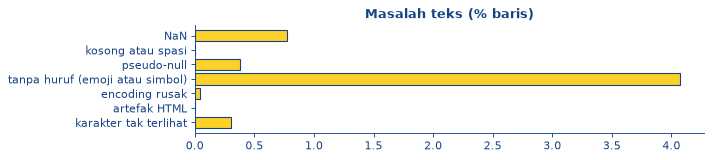

Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,"Korpus berisi banyak baris kosong, simbol, atau stiker. Label pada baris ini tidak bermakna.","Buat aturan filter yang transparan. Untuk test, tetap prediksi dengan fallback kelas mayoritas.",Bandingkan skor dengan dan tanpa baris itu.
●,Sedang,"Noise nyata, tetapi tidak dominan.","Filter di train, tetap siapkan fallback di test.",Lihat 30 contoh sebelum membuang.
,Sedikit,Kualitas dasar baik.,Cukup catat jumlahnya.,-


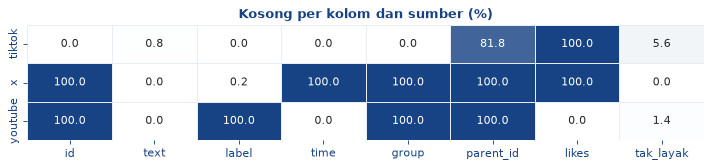

Aktif,Kondisi,Artinya,Aksi,Cara uji
,Besar,Kerusakan terkait sumber: membuang baris akan menggeser komposisi sumber.,Jangan buang sembarangan. Laporkan per sumber.,Bandingkan komposisi sumber sebelum dan sesudah filter.
●,Kecil,Kerusakan tidak terkait sumber.,Filter global aman.,-


In [6]:
M = "02"
s = T.str.strip()
Q = {
    "NaN": df[TEXT].isna(),
    "kosong atau spasi": df[TEXT].notna() & s.eq(""),
    "pseudo-null": s.str.lower().isin(["nan", "null", "none", "-", "n/a", "[sticker]"]),
    "tanpa huruf (emoji atau simbol)": s.ne("") & ~s.str.contains(r"[^\W\d_]"),
    "encoding rusak": s.str.contains("[ÃÂð]"),
    "artefak HTML": s.str.contains(r"<[a-z/][^>]*>|&[a-z]+;"),
    "karakter tak terlihat": s.str.contains("[\u200b-\u200f\ufeff]"),
}
bars(pd.Series({k: pct(v) for k, v in Q.items()}), "Masalah teks (% baris)", c=GOLD)
save("02_kualitas")
bad = Q["NaN"] | Q["kosong atau spasi"] | Q["pseudo-null"] | Q["tanpa huruf (emoji atau simbol)"]
decide("bad_text", pct(bad), f"({bad.sum():,} baris)")
if has(SOURCE):
    heat(
        df.drop(columns=[SOURCE]).isna().assign(tak_layak=bad).groupby(df[SOURCE]).mean() * 100,
        "Kosong per kolom dan sumber (%)",
        "02_missing",
    )
    b = bad.groupby(df[SOURCE]).mean() * 100
    decide("miss_bias", b.max() - b.min())
else:
    skip("miss_bias")

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">03 · Sumber data</h2>

**Pertanyaan:** apakah semua sumber berbentuk sama? Jika tidak, preprocessing dan validasi tunggal berisiko.

,n,median_kata,p95_kata,dup_%,emoji_%,url_%
src,,,,,,
tiktok,57362,7.00,33.00,44.75,37.77,3.64
x,1102,17.00,41.00,0.09,0.00,0.00
youtube,4777,9.00,43.00,26.56,20.47,0.06


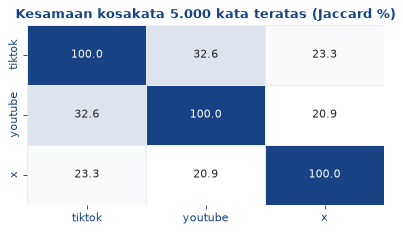

Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Lebih dari satu,Dataset gabungan: gaya bahasa dan cara pengumpulan bisa berbeda.,Laporkan semua statistik per sumber. Uji model per sumber.,Leave-one-source-out (modul 16).
,Satu,Tidak ada variasi sumber yang terlihat.,Lewati analisis sumber.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Sangat berbeda,"Sumber punya bentuk teks berbeda, sehingga MAX_LEN dan bobot TF-IDF bisa bias.",Pertimbangkan fitur sumber dan MAX_LEN dari sumber terpanjang.,Skor per sumber dengan fitur yang sama.
,Mirip,Bentuk teks setara.,Preprocessing tunggal cukup.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Tumpang tindih besar,"Kosakata sumber mirip, sehingga pengalihan domain cenderung ringan.",Model tunggal layak.,Skor per sumber.
●,Tumpang tindih kecil,Sumber memakai kosakata berbeda: model satu sumber bisa jatuh di sumber lain.,Uji domain shift. Char n-gram dan embedding layak diuji.,"Latih di satu sumber, uji di sumber lain."


In [7]:
M = "03"
if has(SOURCE):
    g = pd.DataFrame(
        {
            "src": df[SOURCE],
            **F,
            "dup": T.duplicated(),
            "emoji": T.str.contains(EMOJI),
            "url": T.str.contains(r"@\w+|https?://"),
        }
    ).groupby("src")
    prof = g.agg(
        n=("char", "size"), median_kata=("word", "median"), p95_kata=("word", lambda x: x.quantile(0.95))
    )
    show(prof.join(g[["dup", "emoji", "url"]].mean().mul(100).add_suffix("_%")), cap="Profil per sumber")
    vocab = {
        k: {w for w, _ in Counter(w for t in TOK[df.loc[idx, SOURCE] == k] for w in t).most_common(5000)}
        for k in df[SOURCE].dropna().unique()
    }
    J = pd.DataFrame({a: {b: jac(vocab[a], vocab[b]) * 100 for b in vocab} for a in vocab})
    if len(J) > 1:
        heat(J, "Kesamaan kosakata 5.000 kata teratas (Jaccard %)", "03_vocab", size=(5, 3))
    decide("src_n", len(vocab))
    decide("src_len", prof.median_kata.max() / max(prof.median_kata.min(), 1))
    decide("src_vocab", J.where(~np.eye(len(J), dtype=bool)).min().min() if len(J) > 1 else None)
else:
    skip("src_n", "src_len", "src_vocab")

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">04 · Panjang & struktur teks</h2>

**Pertanyaan:** teks pendek atau panjang? Berapa `MAX_LEN` yang tepat? Jumlah kata tidak sama dengan jumlah token, jadi token diukur dengan tokenizer kandidat.

,mean,std,min,50%,90%,95%,99%,max
karakter,69.31,88.79,0.00,44.00,150.00,213.00,413.00,2170.00
kata,11.63,14.15,0.00,8.00,25.00,35.00,67.00,351.00
kalimat,1.36,1.05,1.00,1.00,2.00,3.00,6.00,27.00
token,17.15,18.05,2.00,12.00,35.00,46.00,83.00,290.00


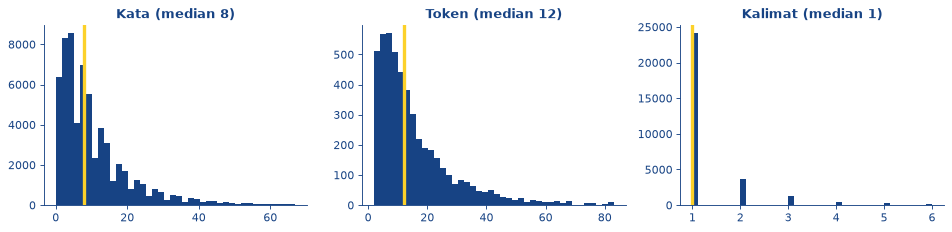

Saran MAX_LEN (p95 token, kelipatan 16): 48


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Teks panjang,Dokumen seperti artikel. Truncation bisa membuang isi.,"Chunking, ringkas dulu, atau head+tail. Sentence-level layak.","Bandingkan head, tail, dan chunk."
,Teks sedang,Satu sampai beberapa kalimat.,Word n-gram dan transformer standar.,TF-IDF vs transformer pada fold sama.
●,Teks pendek,Konteks sedikit dan sinyal per kata besar.,Word + char n-gram sebagai baseline. Jangan buang kata.,"Ablation word, char, union (modul 17)."


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Sangat bervariasi,Ada ekor panjang. Padding statis boros.,Dynamic padding dan length bucketing. Normalisasi L2 penting.,Skor per bucket panjang.
,Cukup seragam,Panjang relatif stabil.,MAX_LEN tetap cukup.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak terpotong,MAX_LEN 128 membuang banyak isi.,"Naikkan MAX_LEN atau chunking, dengan biaya VRAM.",Bandingkan MAX_LEN 128 dan 256.
,Sebagian terpotong,Ekor kecil terpotong.,MAX_LEN sekitar p95 token.,Skor pada teks terpanjang.
●,Hampir tidak ada,"MAX_LEN bisa lebih kecil dari 128, jadi batch lebih besar.",Pakai p99 token sebagai MAX_LEN.,Throughput sebelum dan sesudah.


In [8]:
M = "04"
if (MODELS / TOKENIZER).exists():
    from transformers import AutoTokenizer

    tok = AutoTokenizer.from_pretrained(str(MODELS / TOKENIZER), local_files_only=True)
    ntok = pd.Series(
        [len(i) for i in tok(S.sample(min(5000, len(S)), random_state=SEED).tolist())["input_ids"]]
    )
else:
    ntok = (S.str.split().str.len() * 1.4 + 2).astype(int)
    print("Tokenizer tidak ada: token diperkirakan 1,4 x kata + 2")
sents = S.map(lambda x: max(1, len([p for p in re.split(r"[.!?]+\s*", x) if p.strip()])))
show(
    pd.DataFrame({"karakter": F.char, "kata": F.word, "kalimat": sents, "token": ntok})
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .T.drop(columns="count"),
    cap="Sebaran panjang",
)
_, ax = plt.subplots(1, 3, figsize=(12, 3))
hist(F.word, "Kata", ax[0])
hist(ntok, "Token", ax[1])
hist(sents, "Kalimat", ax[2])
save("04_panjang")
print("Saran MAX_LEN (p95 token, kelipatan 16):", int(np.ceil(ntok.quantile(0.95) / 16) * 16))
decide("len", F.word.median())
decide("len_var", F.word.quantile(0.95) / max(F.word.median(), 1))
decide("tok_cut", pct(ntok > 128))

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">05 · Waktu & metadata</h2>

**Pertanyaan:** volumenya merata atau didorong kejadian? Random split masih mewakili kondisi test?

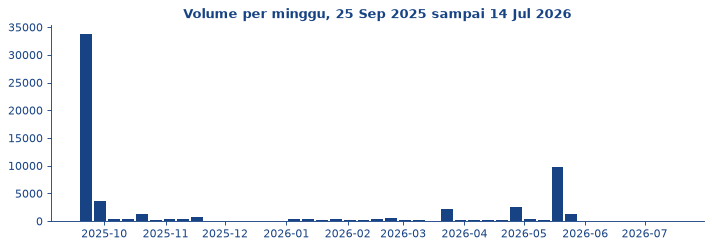

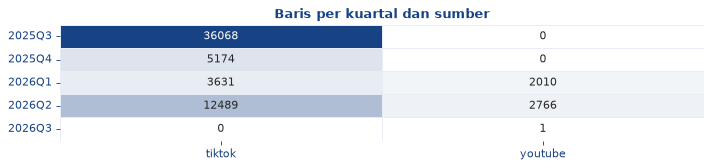

Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Kolom waktu tidak andal atau tidak ada untuk sebagian sumber.,Jangan pakai split waktu global. Analisis per sumber yang valid.,Cek format per sumber.
●,Sedikit,Kolom waktu bisa dipakai.,Boleh split waktu dan fitur tren.,Bandingkan rentang train dan test.


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Sangat terkonsentrasi,"Korpus didominasi beberapa kejadian. Model belajar kejadian, bukan topik umum.","Laporkan proporsi, bukan jumlah. Uji split waktu atau split kejadian.",Random vs split waktu.
,Cukup merata,Tidak ada lonjakan dominan.,"Random split lebih aman, kecuali test jelas lebih baru.",Cek rentang test.


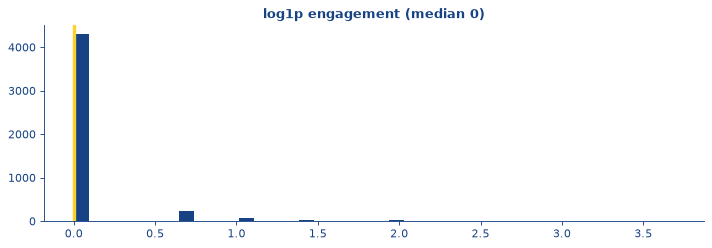

Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Mayoritas nol,Target regresi sangat miring.,"log1p, model dua tahap, RMSLE. Fitur konteks penting.",Bandingkan RMSE log dan mentah.
,Tidak dominan,"Target lebih seimbang, tetapi tetap cek skew.",log1p sebagai default.,Plot residual.


In [9]:
M = "05"
if has(TIME):
    ts = pd.to_datetime(df[TIME], errors="coerce", utc=True, format="mixed").dt.tz_localize(None)
    v = ts.dt.to_period("W").value_counts().sort_index()
    plt.figure()
    plt.bar(v.index.to_timestamp(), v.values, width=6, color=NAVY)
    plt.title(f"Volume per minggu, {ts.min():%d %b %Y} sampai {ts.max():%d %b %Y}")
    save("05_volume")
    if has(SOURCE):
        heat(
            pd.crosstab(ts.dt.to_period("Q").astype(str), df[SOURCE]),
            "Baris per kuartal dan sumber",
            "05_sumber",
            ".0f",
        )
    decide("time_bad", pct(ts.isna()))
    decide("time_burst", 100 * v.sort_values(ascending=False).head(max(1, len(v) // 10)).sum() / v.sum())
else:
    skip("time_bad", "time_burst")
if has(ENGAGE):
    e = pd.to_numeric(df[ENGAGE], errors="coerce").dropna()
    hist(np.log1p(e), "log1p engagement")
    save("05_engagement")
    decide("engage", pct(e == 0), f"dari {len(e):,} baris")
else:
    skip("engage")

<div style="background:#174384;color:#fcd12a;padding:10px 16px;font-size:20px;font-weight:700;border-radius:3px;margin-top:14px">Lapis B · Bahasa</div>

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">06 · Bahasa & campur kode</h2>

**Pertanyaan:** perlu model multibahasa? Deteksi memakai kata penanda dari NusaX. Batas ketat (dua kata penanda) presisinya lebih baik, batas longgar (satu kata) menjadi batas atas kasar.

,ketat_%,longgar_%
text,,
Indonesia,99.76,98.54
Jawa,0.13,0.81
Sunda,0.03,0.19
Bali,0.00,0.08
Ngaju,0.00,0.07
Inggris,0.07,0.07
Banjar,0.00,0.07
Aceh,0.00,0.05
Madura,0.00,0.05


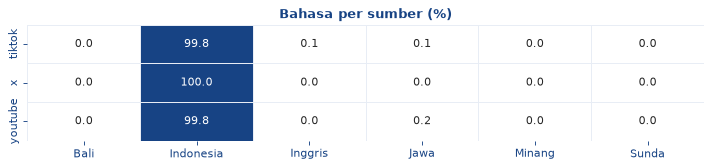

Contoh bahasa daerah:
  - lah yo ngono piye
  - disini dikasih makan ayam rasane ora ngalor ngidol, wkwkwk
  - Gak   yo     lingkungane   gak   kanggo   sung   kanggo  mung   ordal   yg   disukai   pen
  - sopo seng di milih nomer 2 komen o gage


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Cukup banyak,"Bahasa daerah nyata di data, dan model Indonesia bisa turun di sini.",Coba NusaBERT. Evaluasi per bahasa. Char n-gram tetap dipakai.,F1 per bahasa (modul 17).
,Kecil,Ada tetapi efeknya ke skor total terbatas.,Tanpa alur khusus. Baca sampel untuk slide.,Skor pada subset bahasa daerah.
●,Sangat kecil,Hampir semua teks Indonesia.,Tidak perlu model multibahasa.,Baca sampel batas longgar.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Campuran Inggris berarti.,Pertimbangkan encoder multibahasa dan cek kosakata model.,IndoBERT vs multibahasa.
●,Sedikit,Inggris hanya sisipan.,Model Indonesia cukup.,-


In [10]:
M = "06"
MARK = {k: set(v.split()) for k, v in LANG_MARKERS.items()}


def detect(x, hits=2):
    w = toks(x)
    s = set(w)
    if len(w) >= 3 and sum(t in EN for t in w) / len(w) >= 0.3:
        return "eng"
    best = max(MARK, key=lambda k: len(s & MARK[k]))
    return best if len(s & MARK[best]) >= hits else "ind"


lang, loose = S.map(detect), S.map(lambda x: detect(x, 1))
show(
    pd.DataFrame(
        {
            "ketat_%": lang.value_counts(normalize=True) * 100,
            "longgar_%": loose.value_counts(normalize=True) * 100,
        }
    )
    .fillna(0)
    .rename(index=LANG_NAMES)
    .sort_values("longgar_%", ascending=False),
    cap="Porsi bahasa",
)
if has(SOURCE):
    heat(
        pd.crosstab(df.loc[idx, SOURCE], lang.map(LANG_NAMES), normalize="index") * 100,
        "Bahasa per sumber (%)",
        "06_sumber",
    )
print(
    "Contoh bahasa daerah:",
    *S[~lang.isin(["ind", "eng"])]
    .sample(min(4, (~lang.isin(["ind", "eng"])).sum()), random_state=SEED)
    .map(clip),
    sep="\n  - ",
)
decide("lang_local", pct(~lang.isin(["ind", "eng"])), f"(longgar {pct(~loose.isin(['ind', 'eng']))}%)")
decide("lang_en", pct(lang == "eng"))

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">07 · Noise & ejaan</h2>

**Pertanyaan:** seberapa informal teksnya? Hasilnya menentukan apa yang dibersihkan dan apa yang dipertahankan.

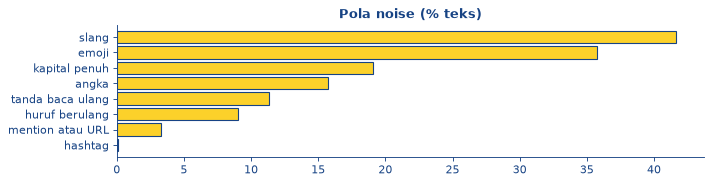

Contoh variasi ejaan: [(np.str_('manfaaat'), 'manfaat'), (np.str_('kapanpun'), 'apapun'), (np.str_('bedah'), 'beda'), (np.str_('alhamdullilah'), 'alhamdulillah'), (np.str_('katna'), 'kata'), (np.str_('ssuai'), 'sesuai'), (np.str_('pengeloa'), 'pengelola'), (np.str_('menuny'), 'menunya'), (np.str_('namnnya'), 'namanya'), (np.str_('cumah'), 'cuma')]


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Banyak,Bahasa informal dominan.,Uji varian mentah vs normalisasi. Model teks sosial (IndoBERTweet) layak jadi kandidat utama.,Ablation slang (modul 17).
,Sedang,Campuran formal dan informal.,Normalisasi hanya sebagai saklar.,Ablation slang.
,Sedikit,Teks cenderung baku.,Model teks formal (IndoBERT) layak diuji.,IndoBERT vs IndoBERTweet.


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Banyak,Emoji bisa membawa sinyal sikap.,Pertahankan atau ubah jadi kata. Pastikan tokenizer tidak membuangnya.,Ablation emoji (modul 17).
,Sedikit,Efeknya kecil.,"Boleh diabaikan, tetapi jangan buang tanpa uji.",-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Hashtag bisa menunjukkan sikap atau label bocor.,Pecah jadi kata. Cek apakah berkorelasi langsung dengan label.,Skor dengan dan tanpa hashtag.
●,Sedikit,Tidak berpengaruh besar.,Biarkan.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Token ini bisa menjadi sidik sumber atau spam.,Ganti dengan penanda. IndoBERTweet memakai @USER dan HTTPURL.,Kata pembeda per kelas.
●,Sedikit,Dampak kecil.,"Ganti dengan penanda, tanpa uji khusus.",-


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Banyak,Pemanjangan huruf memecah kosakata.,Pangkas jadi maksimal dua huruf. Char n-gram tahan terhadap ini.,Skor dengan pemangkasan.
,Sedikit,Dampak kecil.,"Pangkas tetap murah, tetapi opsional.",-


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Banyak,"Huruf kapital bisa membawa intensitas, dan lowercase menghilangkannya.",Tambah fitur rasio kapital. Pilih model cased bila butuh entitas.,Skor dengan fitur kapital.
,Sedikit,Lowercase aman untuk klasifikasi.,Lowercase.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Tinggi,Banyak salah ketik atau variasi ejaan.,Char n-gram dan model subword layak. Jangan koreksi agresif.,Word vs char (modul 17).
●,Rendah,Ejaan cukup stabil.,Word n-gram cukup sebagai awal.,Word vs union.


In [11]:
M = "07"
from rapidfuzz import fuzz, process

NOISE = {
    "slang": r"\b(?:" + "|".join(SLANG) + r")\b",
    "emoji": EMOJI,
    "hashtag": r"#\w+",
    "mention atau URL": r"@\w+|https?://|www\.",
    "huruf berulang": r"([A-Za-z])\1{2,}",
    "kapital penuh": r"\b[A-Z]{3,}\b",
    "tanda baca ulang": r"[!?.]{2,}",
    "angka": r"\d",
}
n = pd.Series(
    {k: pct(S.str.contains(v, flags=re.I if k == "slang" else 0)) for k, v in NOISE.items()}
).sort_values(ascending=False)
bars(n, "Pola noise (% teks)", c=GOLD)
save("07_noise")
cnt = Counter(w for t in TOK for w in t)
top, rare = (
    [w for w, _ in cnt.most_common(500) if len(w) >= 4],
    [w for w, c in cnt.items() if c <= 2 and len(w) >= 5],
)
rare = list(np.random.default_rng(SEED).permutation(rare)[:2000])
hits = [(w, m[0]) for w in rare if (m := process.extractOne(w, top, scorer=fuzz.ratio, score_cutoff=85))]
print("Contoh variasi ejaan:", hits[:10])
for k, c in dict(
    n_slang="slang",
    n_emoji="emoji",
    n_hashtag="hashtag",
    n_url="mention atau URL",
    n_repeat="huruf berulang",
    n_upper="kapital penuh",
).items():
    decide(k, n[c])
decide("n_variant", 100 * len(hits) / max(1, len(rare)))

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">08 · Kosakata & n-gram</h2>

**Pertanyaan:** word n-gram cukup, atau kosakatanya terlalu panjang ekornya? Kata apa yang khas domain?

,nilai
token,340844.00
tipe kata,21804.00
type-token ratio,0.06
hapax % tipe,44.35
kata untuk 90% token,3898.00
kemiringan Zipf,-1.21


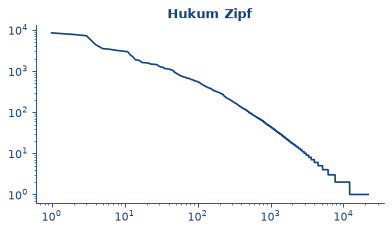

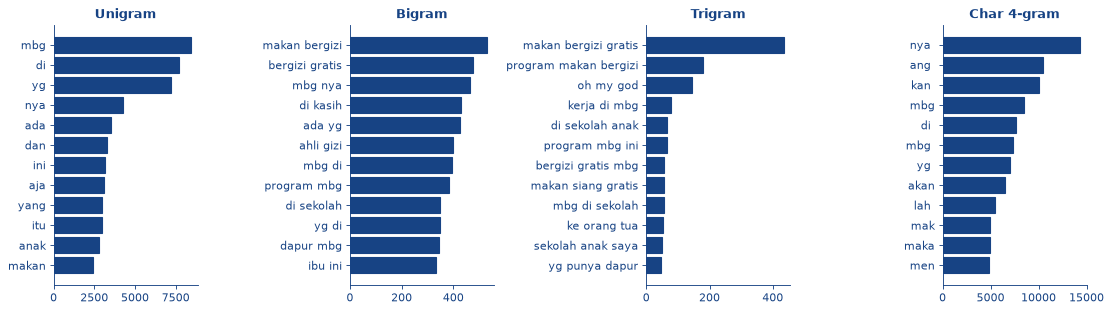

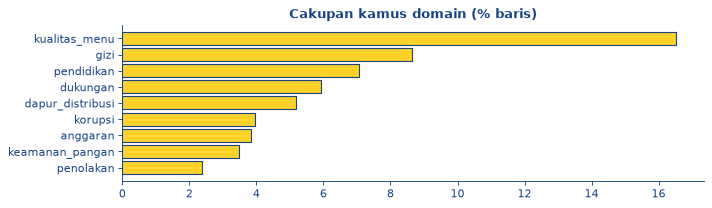

Aktif,Kondisi,Artinya,Aksi,Cara uji
,Ekor panjang,Banyak kata tidak akan terlihat lagi di test.,min_df tinggi untuk word. Char n-gram atau embedding subword.,OOV test dan skor char.
●,Wajar,Kosakata tidak terlalu berekor panjang.,Word TF-IDF sudah kuat.,Skor word sebagai baseline.


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Besar,"Banyak kata berimbuhan, sehingga stemming bisa menyatukan sinyal, juga bisa menghapus nuansa.",Uji stem pada word TF-IDF. Jangan untuk transformer.,Ablation stem (modul 17).
,Kecil,Stemming sedikit mengubah kosakata.,Lewati stemming.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Tinggi,Kamus mewakili korpus: label lemah dan fitur aspek layak.,Audit presisi 30 sampel per aspek.,Fitur kamus dalam ablation.
,Sedang,Sebagian saja terwakili.,Perluas kamus dari kata khas per klaster.,Hitung cakupan sebelum dan sesudah.
,Rendah,Kamus tidak cocok dengan korpus. Bisa jadi topik data berbeda.,"Buat kamus dari data, jangan dipaksakan.",Topic modeling lebih dulu.


In [12]:
M = "08"
from sklearn.feature_extraction.text import CountVectorizer

fr = pd.Series(cnt).sort_values(ascending=False)
N = fr.sum()
r = np.arange(1, len(fr) + 1)
slope = np.polyfit(np.log(r[:5000]), np.log(fr.values[:5000]), 1)[0]
show(
    pd.Series(
        {
            "token": N,
            "tipe kata": len(fr),
            "type-token ratio": len(fr) / N,
            "hapax % tipe": pct(fr == 1),
            "kata untuk 90% token": int((fr.cumsum() / N < 0.9).sum()),
            "kemiringan Zipf": slope,
        },
        name="nilai",
    ),
    cap="Ringkasan kosakata",
)
plt.figure(figsize=(5, 3))
plt.loglog(r, fr.values, color=NAVY)
plt.title("Hukum Zipf")
save("08_zipf")
_, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, (name, kw) in zip(
    ax,
    {
        "Unigram": dict(ngram_range=(1, 1)),
        "Bigram": dict(ngram_range=(2, 2)),
        "Trigram": dict(ngram_range=(3, 3)),
        "Char 4-gram": dict(analyzer="char_wb", ngram_range=(4, 4)),
    }.items(),
):
    v = CountVectorizer(min_df=2, max_features=20000, **kw)
    X = v.fit_transform(S)
    bars(pd.Series(np.asarray(X.sum(0)).ravel(), v.get_feature_names_out()).nlargest(12), name, a)
save("08_ngram")
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
types = fr.index[:3000]
D = (
    pd.DataFrame({k: T.str.contains(rf"\b(?:{v})", case=False) for k, v in DOMAIN.items()})
    if DOMAIN
    else pd.DataFrame(index=T.index)
)
if DOMAIN:
    bars((D.mean() * 100).sort_values(ascending=False), "Cakupan kamus domain (% baris)", c=GOLD)
    save("08_domain")
decide("hapax", pct(fr == 1))
decide("stem", 100 * (1 - len({stemmer.stem(w) for w in types}) / len(types)), "pada 3.000 kata teratas")
decide("domain_cov", pct(D.any(axis=1)) if DOMAIN else None)

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">09 · Stopword & kata fungsi</h2>

**Pertanyaan:** aman membuang stopword? Kata seperti `tidak`, `belum`, dan `seharusnya` bisa membalik makna.

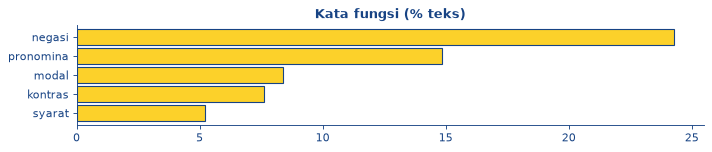

label,negatif,netral,positif
text,,,
ada negasi,84.12,2.17,13.72
tanpa negasi,59.17,9.88,30.95


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Besar,"Kata fungsi banyak, tetapi belum tentu tidak berguna.",Buang hanya untuk topik dan word cloud.,Ablation stopword (modul 17).
●,Kecil,Teks padat kata isi.,Tidak perlu membuang stopword.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Banyak,Negasi berpeluang membalik makna.,Jangan buang stopword secara agresif. Pertahankan bigram dan negasi.,F1 pada subset negasi (modul 17).
,Sedikit,Efek negasi terbatas.,Tetap pertahankan: biayanya nol.,-


In [13]:
M = "09"
fn = pd.Series({k: pct(S.str.contains(v, case=False)) for k, v in FUNC.items()}).sort_values(ascending=False)
bars(fn, "Kata fungsi (% teks)", c=GOLD)
save("09_fungsi")
if tg and df[tg[0]].nunique() <= 20:
    y9 = df.loc[idx, tg[0]].where(lambda c: ~c.isin(LABEL_DROP))
    m = y9.notna()
    show(
        pd.crosstab(
            S[m].str.contains(FUNC["negasi"], case=False).map({True: "ada negasi", False: "tanpa negasi"}),
            y9[m],
            normalize="index",
        )
        * 100,
        cap="Sebaran kelas menurut negasi (%)",
    )
decide("stop", 100 * sum(c for w, c in cnt.items() if w in STOP) / N)
decide("neg", fn["negasi"])

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">10 · Struktur kalimat</h2>

**Pertanyaan:** urutan kata dan struktur penting? Bundle tidak membawa parser dependency, jadi modul ini memakai proxy cepat. Parser juga sering keliru pada slang. Awalan `di-` hanya tanda kasar untuk pasif.

In [14]:
M = "10"
show(
    pd.Series(
        {
            "kalimat per teks (median)": sents.median(),
            "tanpa tanda baca akhir %": pct(~S.str.strip().str.contains(r"[.!?]$")),
            "tanya %": pct(S.str.contains(r"\?")),
            "kutipan %": pct(S.str.contains('"')),
            "awalan di- %": pct(S.str.contains(r"\bdi[a-z]{3,}", case=False)),
            "kontras %": fn["kontras"],
            "syarat %": fn["syarat"],
        },
        name="nilai",
    ),
    cap="Proxy struktur",
)
decide("sent", sents.median())
decide("contrast", pct(S.str.contains(FUNC["kontras"] + "|" + FUNC["syarat"], case=False)))

,nilai
kalimat per teks (median),1.00
tanpa tanda baca akhir %,88.28
tanya %,5.50
kutipan %,3.08
awalan di- %,14.62
kontras %,7.62
syarat %,5.23


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Multi kalimat,Struktur dokumen berguna.,Sentence-level atau ringkasan ekstraktif layak.,Dokumen vs agregasi kalimat.
●,Satu atau dua,"Struktur kalimat kurang berguna, dan tanda baca sering tidak ada.",Modelkan per dokumen.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Banyak,"Satu teks memuat dua sikap, sehingga urutan kata penting.",Transformer layak. ABSA lebih tepat daripada satu label.,Error pada subset kontras.
,Sedikit,Bag-of-words mungkin cukup.,Uji baseline dulu.,TF-IDF vs transformer.


<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">11 · Semantik</h2>

**Pertanyaan:** kemiripan ada pada kata atau makna? Hasil modul ini menentukan layak tidaknya embedding, cross-encoder, dan algoritma klaster. Hanya diagnosis: embedding belum tentu jadi fitur final.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Kemiripan pasangan acak: median 0.843 | tetangga terdekat: median 0.927 | ambang mirip 0.956


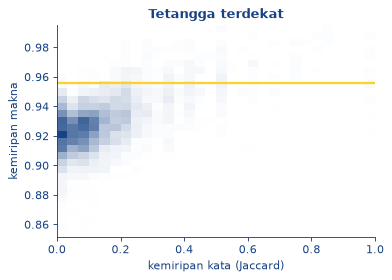

Mirip makna, beda kata:
  - sik diam semuanya  <->  tutup semua ajalah
  - betul bangett Bu  <->  bener bangett Buu,
  - ayamnya banyak bangett di aku cuma 4 potongan kecil 😭😭😭  <->  Ditempatku ada yg dpt mie ayam ,ayamnya cuma 4 potong kecil2 bgt ..
Mirip kata, beda negasi:


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Jelas lebih dekat,Embedding menemukan struktur: teks mirip benar-benar berkumpul.,Klaster dan pencarian semantik layak. Periksa kebocoran semantik di split.,Group fold berdasarkan klaster.
●,Hampir sama,Teks beragam atau embedding kurang membedakan.,Klaster bisa lemah. Bandingkan model embedding.,Baca tetangga terdekat.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,"Ada kedekatan makna yang tidak tertangkap kata. Ambang dari pasangan acak, tetapi tetap baca contohnya.",Embedding dan transformer berpotensi menambah nilai.,Linear di atas embedding vs TF-IDF.
●,Sedikit,"Kemiripan terutama leksikal, atau komentar pendek jarang berparafrase.",Baseline leksikal bisa sulit dikalahkan.,"Baseline dulu, transformer sebagai taruhan."


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Kata mirip tetapi makna bisa berlawanan.,"Pertahankan negasi. Untuk pasangan, cross-encoder atau NLI layak.",Error pada pasangan seperti ini.
●,Sedikit,Jebakan ini jarang.,Tidak butuh perlakuan khusus.,-


In [15]:
M = "11"


def embed(texts, bs=64):
    """E5 bila ada. Tanpa model: TF-IDF + SVD. Vektor ternormalisasi."""
    if (MODELS / EMB).exists():
        from sentence_transformers import SentenceTransformer

        global _st
        _st = globals().get("_st") or SentenceTransformer(str(MODELS / EMB), local_files_only=True)
        return _st.encode(
            ["passage: " + t for t in texts],
            batch_size=bs,
            normalize_embeddings=True,
            show_progress_bar=False,
        )
    from sklearn.decomposition import TruncatedSVD
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.preprocessing import normalize

    X = TfidfVectorizer(max_features=50000).fit_transform(texts)
    return normalize(TruncatedSVD(min(128, X.shape[1] - 1), random_state=SEED).fit_transform(X))


pick = T[F.word >= 3].drop_duplicates()
pick = pick.sample(min(N_SEM, len(pick)), random_state=SEED)
u = pick.tolist()
t0 = time.time()
E = embed(u)
sec_embed = (time.time() - t0) / len(u)
sim = E @ E.T
np.fill_diagonal(sim, -1)
nn, top = sim.argmax(1), sim.max(1)
sets = [set(toks(x)) for x in u]
lex = np.array([jac(sets[i], sets[j]) for i, j in enumerate(nn)])
neg = np.array([bool(re.search(FUNC["negasi"], x, re.I)) for x in u])

# Tiap model punya skala kemiripan sendiri, jadi ambang diambil dari pasangan acak, bukan angka mutlak.
rng = np.random.default_rng(SEED)
rand = sim[rng.integers(0, len(u), 2_000_000), rng.integers(0, len(u), 2_000_000)]
thr = np.quantile(rand, 1 - 1 / (10 * len(u)))
para, close = (top >= thr) & (lex < 0.3), lex >= 0.6
clash = close & (neg != neg[nn])
print(
    f"Kemiripan pasangan acak: median {np.median(rand):.3f} | tetangga terdekat: median {np.median(top):.3f} | ambang mirip {thr:.3f}"
)

plt.figure(figsize=(5, 3.6))
plt.hist2d(lex, top, bins=30, cmap=SEQ)
plt.axhline(thr, color=GOLD, lw=2)
plt.xlabel("kemiripan kata (Jaccard)")
plt.ylabel("kemiripan makna")
plt.title("Tetangga terdekat")
save("11_kata_makna")
for name, m in {"Mirip makna, beda kata": para, "Mirip kata, beda negasi": clash}.items():
    print(
        name + ":",
        *[f"{clip(u[i], 70)}  <->  {clip(u[nn[i]], 70)}" for i in np.where(m)[0][:3]],
        sep="\n  - ",
    )
decide("sem_nn", np.median(top) - np.median(rand))
decide("sem_para", pct(para))
decide("sem_clash", pct(clash[close]) if close.any() else None, f"dari {close.sum()} pasangan")

Silhouette KMeans: {5: 0.065, 10: 0.053, 20: 0.053} | klaster HDBSCAN: 25


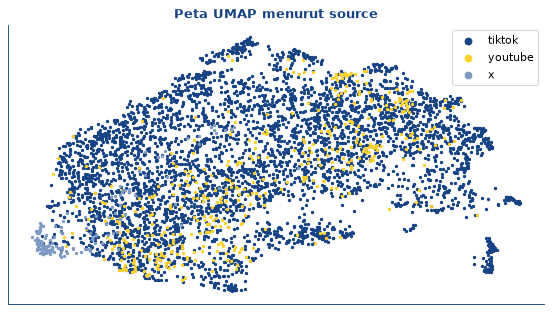

,kata teratas
klaster 16,"yg, mbg, program, ga, gak, aja, ya, salah"
klaster 15,"ibu, banget, keren, setuju, suka, cara, mewakili, si"
klaster 22,"mbg, yg, program, dapur, aja, gak, buat, ya"
klaster 4,"ya, yg, mbg, ga, lu, sih, kan, kok"
klaster 2,"rb, per, jt, k, mbg, yg, ribu, aja"
klaster 14,"makan, gratis, bergizi, program, anak, indonesia, mbg, gizi"


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Tinggi,Banyak teks tidak masuk klaster padat.,"Untuk peta tema penuh, KMeans atau NMF lebih praktis. HDBSCAN untuk tema inti.",Baca sampel noise.
,Rendah,Sebagian besar teks masuk klaster. Cek juga ukuran klaster terbesar.,HDBSCAN atau BERTopic layak bila klaster tidak raksasa.,Stabilitas antar-seed.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Satu klaster menelan hampir semua,Hasilnya tidak berguna sebagai peta tema.,Perkecil min_cluster_size atau pakai KMeans atau NMF.,Baca kata teratas tiap klaster.
●,Tersebar,Ada beberapa tema dengan ukuran wajar.,Layak dibaca dan dinamai.,Stabilitas antar-seed.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Terpisah,Klaster cukup jelas.,Klaster bisa dilaporkan sebagai segmen.,Koherensi dan stabilitas.
●,Tumpang tindih,"Batas klaster lemah, seperti umumnya komentar pendek.","Laporkan sebagai tema, bukan klaster tegas. Pakai soft assignment.",Baca 20 contoh tiap klaster.


In [16]:
import hdbscan, umap
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X5 = umap.UMAP(n_components=5, n_neighbors=15, min_dist=0, random_state=SEED).fit_transform(E)
XY = umap.UMAP(n_components=2, n_neighbors=15, random_state=SEED).fit_transform(E)
km = {k: KMeans(k, n_init=3, random_state=SEED).fit_predict(E) for k in (5, 10, 20)}
sil = {
    k: silhouette_score(E, v, metric="cosine", sample_size=2000, random_state=SEED) for k, v in km.items()
}  # di ruang asli: UMAP membuatnya terlalu optimistis
hd = hdbscan.HDBSCAN(min_cluster_size=max(10, len(u) // 200), cluster_selection_method="leaf").fit_predict(X5)
print("Silhouette KMeans:", {k: round(v, 3) for k, v in sil.items()}, "| klaster HDBSCAN:", hd.max() + 1)
col = next((c for c in (SOURCE, *tg) if has(c) and df[c].nunique() <= 6), None)
c = df.loc[pick.index, col].astype(str) if col else pd.Series("semua", index=pick.index)
plt.figure(figsize=(7, 4))
for i, k in enumerate(c.value_counts().index):
    plt.scatter(*XY[c.values == k].T, s=4, color=TINT[i % 6], label=k)
plt.legend(markerscale=3)
plt.title(f"Peta UMAP menurut {col or 'teks'}")
plt.xticks([])
plt.yticks([])
save("11_umap")
kw = pd.Series(hd[hd >= 0]).value_counts().head(6).index
show(
    pd.DataFrame(
        {
            f"klaster {i}": [
                ", ".join(
                    w
                    for w, _ in Counter(
                        w for j in np.where(hd == i)[0] for w in sets[j] if w not in STOP
                    ).most_common(8)
                )
            ]
            for i in kw
        }
    ).T.rename(columns={0: "kata teratas"}),
    cap="Klaster terbesar",
)
decide("clu_noise", pct(hd == -1))
decide(
    "clu_big",
    100 * pd.Series(hd[hd >= 0]).value_counts(normalize=True).max() if (hd >= 0).any() else None,
    f"({hd.max() + 1} klaster)",
)
decide("clu_sil", max(sil.values()))

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">12 · Entitas & angka</h2>

**Pertanyaan:** angka dan nama membawa informasi? Kalau ya, hati-hati dengan stemming, lowercase, dan penghapusan angka.

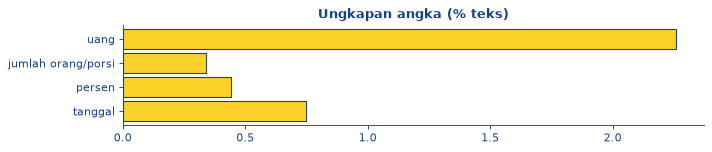

Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,"Uang, jumlah, atau tanggal membawa informasi.",Jangan hapus angka. Pertimbangkan ekstraksi regex.,Skor dengan angka diganti penanda.
●,Sedikit,Angka jarang.,Boleh diganti penanda.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Kapitalisasi masih informatif.,Model cased untuk NER. Simpan offset dan teks asli.,Cased vs uncased.
●,Sedikit,"Kapitalisasi tidak andal, sehingga NER berbasis kapital akan lemah.",Gazetteer atau model yang dilatih pada teks informal.,Recall pada daftar entitas.


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

,n,contoh
tipe,,
PRD,352,"mbg, burger, susu, tempe, sppg, spageti"
PER,107,"mbg, prabowo, tan, dr tan, pak, an*s"
ORG,40,"mbg, bgn, sppg, kepala bgn, paud, forum tempe indonesia fti"
GPE,38,"indonesia, bali, bandung, kalbar, lombok, eropa"
NOR,30,"pemerintah, dpr, bpk, dpr ri, pemerintah.atau, bpp banjar"
QTY,26,"10 bulan, 2hari, 1 minggu, 4 bulanan, 3 tahun, 30 hari,1 thun"
CRD,23,"satu, 19 juta, 3000, satu...jadi, 11/12, tiga"
MON,16,"6 juta, 15k, 10k, 5rbu, 300rb, 10jt"
EVT,13,"pilpres, sembako, sekolah, kelas, mbg, anggaran"


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Banyak,"Entitas banyak, dan bisa menjadi kebocoran atau sinyal.",Hati-hati dengan stemming dan lowercase. Pertimbangkan masking entitas.,Skor dengan entitas dimasking.
,Sedikit,Entitas jarang atau NER gagal pada teks informal.,Baca sampel. Gazetteer mungkin lebih andal.,Audit presisi NER.


In [17]:
M = "12"
NUM = {
    "uang": r"\brp\.?\s?\d|\b\d+\s?(?:rb|ribu|juta|jt|miliar|triliun)\b",
    "jumlah orang/porsi": r"\b\d+\s(?:siswa|murid|anak|korban|orang|porsi|guru)\b",
    "persen": r"\d\s?%|\bpersen\b",
    "tanggal": r"\b\d{1,2}\s(?:jan|feb|mar|apr|mei|jun|jul|agu|sep|okt|nov|des)[a-z]*\b|\b\d{4}-\d{2}-\d{2}\b|\bkemarin\b",
}
nm = pd.Series({k: pct(S.str.contains(v, case=False)) for k, v in NUM.items()})
bars(nm, "Ungkapan angka (% teks)", c=GOLD)
save("12_angka")
decide("num", pct(S.str.contains("|".join(NUM.values()), case=False)))
decide("case", pct(S.str.contains(r"[a-z,]\s[A-Z][a-z]{2,}")))
if (MODELS / NER).exists():
    import torch
    from transformers import pipeline

    ner = pipeline(
        "token-classification",
        model=str(MODELS / NER),
        aggregation_strategy="first",
        device=0 if torch.cuda.is_available() else -1,
        batch_size=32,
    )
    sn = (
        S[S.str.contains("[a-zA-Z]")]
        .sample(min(N_NER, len(S)), random_state=SEED)
        .map(lambda x: re.sub(EMOJI, " ", clip(x, 400)))
        .tolist()
    )
    found = [
        [
            (e["entity_group"], e["word"].strip(" ,.!?'\""))
            for e in r
            if len(re.sub(r"\W", "", e["word"])) >= 3
        ]
        for r in ner(sn)
    ]
    ents = pd.DataFrame([x for r in found for x in r], columns=["tipe", "kata"])
    show(
        ents.groupby("tipe")
        .kata.agg(n="size", contoh=lambda x: ", ".join(x.str.lower().value_counts().head(6).index))
        .sort_values("n", ascending=False),
        10,
        "NER umum pada sampel (audit dulu: teks informal)",
    )
    decide("ent", pct([len(r) > 0 for r in found]))
else:
    skip("ent")

<div style="background:#174384;color:#fcd12a;padding:10px 16px;font-size:20px;font-weight:700;border-radius:3px;margin-top:14px">Lapis C · Modeling</div>

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">13 · Duplikat & redundansi</h2>

**Pertanyaan:** ada kebocoran train-validasi? Berapa volume asli dibanding copypasta? Jangan langsung hapus: frekuensi ulang bisa jadi temuan untuk laporan.

,teks,ulang
0,[Sticker],240
1,betul,47
2,[samaran],46
3,STOP MBG,45
4,setuju,40
5,stop mbg,38
6,betul bu,28
7,mantap,27


Grup near-duplicate terbesar:
  - pendukung fanatik Prabowo anomali 78 ini udah ga ketolong yaa😭 bisa2 nya ada orang yg pedu
  - pendukung fanatik Prabowo anomali 78 ini udah ga ketolong yaa😭 bisa2 nya ada orang yg pedu
  - [samaran]: pendukung fanatik Prabowo anomali 78 ini udah ga ketolong yaa😭 bisa2 nya ada or


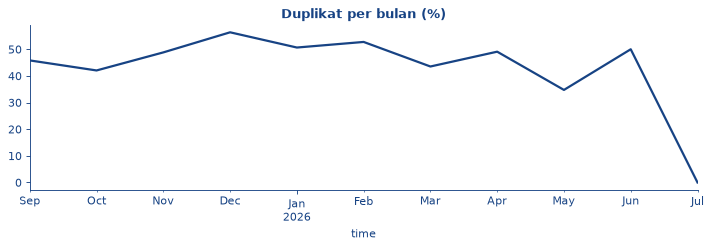

Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Banyak,Copypasta atau scraping ganda. Skor bisa optimistis.,Group fold berdasarkan teks. Laporkan volume asli vs copypasta.,Selisih random vs group (modul 17).
,Sedang,Ada pengulangan.,Tetap pakai group fold.,Selisih random vs group.
,Sedikit,Hampir semua unik.,"Dedup murah, tetapi tidak krusial.",-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Variasi kapital atau tanda baca menyembunyikan duplikat.,"Grup berdasarkan teks ternormalisasi, bukan teks mentah.",Kebocoran antar-fold.
●,Sedikit,Duplikat exact sudah mewakili.,Hash exact cukup.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Template atau kampanye. Satu suara bisa terlihat seperti banyak suara.,Grup MinHash untuk fold. Pisahkan dari opini organik di laporan.,Selisih skor dan baca grup terbesar.
●,Sedikit,Near-duplicate bukan masalah utama.,Grup exact cukup.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Teks melintasi grup: group fold berdasarkan video saja masih bocor.,Gabungkan grup teks dan grup sumber.,Overlap teks antar-fold.
●,Sedikit,Grup yang ada aman.,Group fold biasa.,-


In [18]:
M = "13"
from datasketch import MinHash, MinHashLSH

key = T.map(norm)
ok = key.ne("")
exact, normd = pct(T[ok].duplicated()), pct(key[ok].duplicated())


def near_groups(texts, th=0.8, perm=64, k=5):
    """Grup near-duplicate dengan MinHash pada char k-gram. Kembalikan nomor grup per teks."""
    lsh, parent = MinHashLSH(threshold=th, num_perm=perm), list(range(len(texts)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, t in enumerate(texts):
        m = MinHash(num_perm=perm)
        m.update_batch([t[j : j + k].encode() for j in range(max(1, len(t) - k + 1))])
        for j in lsh.query(m):
            parent[find(i)] = find(j)
        lsh.insert(i, m)
    return np.array([find(i) for i in range(len(texts))])


uk = key[key.str.len() >= 20].drop_duplicates()
uk = uk.sample(min(20000, len(uk)), random_state=SEED)
grp = pd.Series(near_groups(uk.tolist()), index=uk.index)
size = grp.map(grp.value_counts())
tpl = T[ok].value_counts().head(8)
show(pd.DataFrame({"teks": tpl.index.map(clip), "ulang": tpl.values}), cap="Template terbanyak")
print(
    "Grup near-duplicate terbesar:",
    *T[grp[grp == grp.value_counts().index[0]].index[:3]].map(clip),
    sep="\n  - ",
)
if has(TIME):
    plt.figure()
    (T.duplicated().groupby(ts.dt.to_period("M")).mean() * 100).plot(
        color=NAVY, lw=2, title="Duplikat per bulan (%)"
    )
    save("13_waktu")
decide("dup_exact", exact)
decide("dup_norm", normd - exact)
decide("dup_near", pct(size > 1), f"dari {len(uk):,} teks unik")
gc = next((c for c in (GROUP, SOURCE) if has(c)), None)
rep = key[ok & key.duplicated(keep=False)]
decide(
    "dup_cross",
    pct(df.loc[rep.index, gc].groupby(rep).nunique() > 1) if gc and len(rep) else None,
    f"menurut {gc}",
)

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">14 · Pasangan teks</h2>

**Pertanyaan:** untuk NLI, matching, dan similarity: pasangan berbeda pada kata atau makna? Kolom `TEXT_B` dipakai bila ada. Kalau tidak ada, `PARENT` membentuk pasangan balasan-induk.

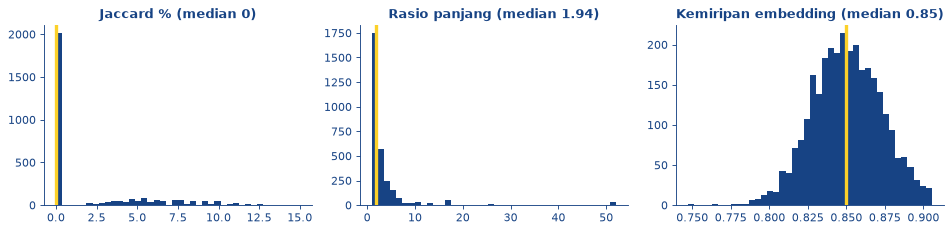

3,000 pasangan | korelasi kata vs makna: 0.33


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Tinggi,"Pasangan mirip secara kata, sehingga fitur overlap kuat tetapi jebakan negasi mungkin.",Fitur overlap dan cross-encoder.,Overlap saja vs cross-encoder.
●,Rendah,"Pasangan beda kata, sehingga butuh pemahaman makna.",Bi-encoder atau cross-encoder. TF-IDF biasa tidak cukup.,TF-IDF vs embedding.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Timpang,"Satu teks jauh lebih panjang, seperti query dan dokumen.",Encoding asimetris. Jangan satukan begitu saja.,Bi-encoder asimetris vs simetris.
●,Seimbang,Bentuk simetris.,Pasangan simetris aman. Tukar urutan bisa jadi augmentasi bila label simetris.,"Skor (a,b) vs (b,a)."


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Jelas lebih dekat dari acak,Pasangan nyata berkaitan dan kemiripan membawa sinyal.,Mulai dari cosine + threshold. Cross-encoder bila kelas bergantung arah atau negasi.,AUC dari kemiripan saja.
●,Dekat dengan acak,Kemiripan saja sulit memisahkan pasangan.,Fitur lain atau cross-encoder.,AUC dari kemiripan saja.


In [19]:
M = "14"
if TEXT_B and has(TEXT_B):
    P = df[[TEXT, TEXT_B]].set_axis(["a", "b"], axis=1)
elif has(PARENT) and has(ID):
    induk = df.drop_duplicates(ID).set_index(ID)[TEXT]
    P = pd.DataFrame({"a": df[TEXT], "b": df[PARENT].map(induk)})
else:
    P = pd.DataFrame(columns=["a", "b"])
P = P.dropna()
if len(P):
    P = P.sample(min(3000, len(P)), random_state=SEED)
    lj = pd.Series([jac(set(toks(a)), set(toks(b))) * 100 for a, b in zip(P.a, P.b)])
    lr = pd.Series([max(len(a), len(b)) / max(1, min(len(a), len(b))) for a, b in zip(P.a, P.b)])
    Ep = embed(P.a.tolist() + P.b.tolist())
    cos = (Ep[: len(P)] * Ep[len(P) :]).sum(1)
    acak = (Ep[: len(P)] * Ep[len(P) :][np.random.default_rng(SEED).permutation(len(P))]).sum(
        1
    )  # pembanding: pasangan diacak
    _, ax = plt.subplots(1, 3, figsize=(12, 3))
    hist(lj, "Jaccard %", ax[0])
    hist(lr, "Rasio panjang", ax[1])
    hist(cos, "Kemiripan embedding", ax[2])
    save("14_pasangan")
    print(f"{len(P):,} pasangan | korelasi kata vs makna: {np.corrcoef(lj, cos)[0, 1]:.2f}")
    decide("pair_lex", lj.median())
    decide("pair_len", lr.median())
    decide(
        "pair_sem",
        float(np.median(cos) - np.median(acak)),
        f"(pasangan {np.median(cos):.2f}, acak {np.median(acak):.2f})",
    )
else:
    skip("pair_lex", "pair_len", "pair_sem")

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">15 · Label & target</h2>

**Pertanyaan:** metrik dan decision layer apa yang tepat? Labelnya manual atau buatan mesin? Kalau tidak ada label, modul ini dilewati dan modul 11 (klaster) menjadi pengganti.

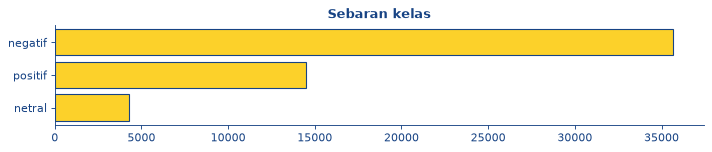

,n,%,median_kata
label,,,
negatif,35666,65.50,9.00
netral,4296,7.89,7.00
positif,14487,26.61,6.00


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Multilabel,Satu baris bisa banyak label.,Binary relevance dengan threshold per label. Micro dan macro-F1.,Threshold per label pada OOF.
,Regresi,Target kontinu.,"RMSE/RMSLE, log1p bila miring. Linear pada TF-IDF.",Plot prediksi vs nilai.
●,Multikelas,Tiga kelas atau lebih.,"Stratified fold, macro-F1, pengali per kelas pada OOF.",Nested multiplier.
,Biner,Dua kelas.,Threshold dari kurva OOF. F1 kelas positif atau PR-AUC.,Nested threshold.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Hampir semua,Supervised penuh.,Fold berlabel langsung. Sisihkan holdout.,CV yang jujur.
●,Sebagian,Banyak baris tanpa label. Label bisa terkumpul pada sumber tertentu.,"Semi-supervised: pseudo-label yakin, validasi hanya pada yang berlabel.",Skor dengan dan tanpa pseudo-label.
,Sangat sedikit,Hampir tanpa label.,"Zero-shot pada sampel, lalu self-training. Gold sendiri bila diizinkan.",Skor pada gold.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Sangat timpang,"Akurasi menyesatkan, dan kelas kecil mudah diabaikan.","Macro-F1, decision layer. Weight atau resampling hanya bila terbukti.",Weight vs decision layer pada fold sama.
●,Timpang,Kelas kecil masih terwakili.,Macro-F1 dan pengali per kelas pada OOF.,Argmax vs nested multiplier.
,Seimbang,Akurasi dan macro-F1 cenderung dekat.,Metrik resmi dari panitia.,Bandingkan keduanya.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,Label berisik atau bergantung konteks. Ada batas atas skor.,Pakai kesepakatan mayoritas di train. Jangan hapus otomatis. Ukur batas atas.,Skor maksimal dari voting per teks.
●,Sedikit,Label konsisten pada teks sama.,Cukup voting mayoritas.,-


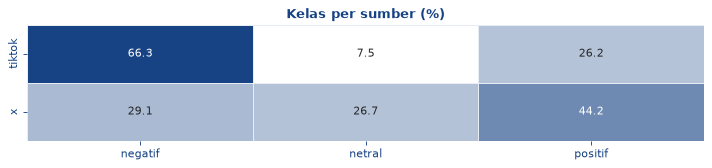

Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Besar,"Label berkorelasi dengan sumber, sehingga model bisa belajar sumber, bukan sentimen. Cara pelabelan mungkin berbeda.",Laporkan per sumber. Hati-hati memakai sumber sebagai fitur.,Leave-one-source-out.
,Kecil,Komposisi kelas stabil antarsumber.,Gabungan aman.,-


,kata khas (log-odds)
negatif,"pendukung, percuma, salahin, fanatik, bubarin, kasian, tolol, kasihan, kacau, kalah"
positif,"best, mantapp, omaygottt, love, mantap, speaking, kerennn, mantappp, sehat2, burgerrrrrrrrrr"
netral,"00, raffi, who, ahmad, tanggal, enter, pontianak, metro, utusan, katsuu"


In [20]:
M = "15"
lab = None
if len(tg) > 1:
    Y = df[tg]
    decide("y_type", 3)
    decide("y_cov", pct(Y.notna().all(axis=1)))
    bars((Y.mean() * 100).sort_values(ascending=False), "Label aktif (%)", c=GOLD)
    save("15_multilabel")
    heat(Y.astype(float).corr(), "Korelasi antarlabel", "15_korelasi", ".2f")
    decide("y_imb", Y.mean().max() / max(Y.mean().min(), 1e-9))
    skip("y_conflict", "y_src", "y_model")
elif tg and pd.api.types.is_numeric_dtype(df[tg[0]]) and df[tg[0]].nunique() > 20:
    hist(df[tg[0]], "Target numerik")
    save("15_target")
    decide("y_type", 2)
    decide("y_cov", pct(df[tg[0]].notna()))
    skip("y_imb", "y_conflict", "y_src", "y_model")
elif tg:
    lab = df[tg[0]].where(~df[tg[0]].isin(LABEL_DROP))
    vc = lab.value_counts()
    bars(vc, "Sebaran kelas", c=GOLD)
    save("15_kelas")
    show(
        pd.DataFrame({"n": vc, "%": vc / vc.sum() * 100, "median_kata": F.word.groupby(lab).median()}),
        cap="Profil kelas",
    )
    decide("y_type", int(len(vc) > 2))
    decide("y_cov", pct(lab.notna()), f"(nilai {LABEL_DROP} dianggap kosong)")
    decide("y_imb", vc.max() / vc.min())
    keys = key[lab.notna()]
    ly = lab[lab.notna()]
    rp = keys.duplicated(keep=False)
    decide(
        "y_conflict",
        pct(ly[rp].groupby(keys[rp]).nunique() > 1) if rp.any() else None,
        f"dari {keys[rp].nunique():,} teks berulang",
    )
    if has(SOURCE) and df.loc[lab.notna(), SOURCE].nunique() > 1:
        ct = pd.crosstab(df.loc[lab.notna(), SOURCE], ly, normalize="index") * 100
        heat(ct, "Kelas per sumber (%)", "15_sumber")
        decide("y_src", (ct.max() - ct.min()).max())
    else:
        skip("y_src")
    tw = T[lab.notna()].sample(min(N_LING, lab.notna().sum()), random_state=SEED)
    cv = CountVectorizer(min_df=5, max_features=30000)
    Xw, names = cv.fit_transform(tw), cv.get_feature_names_out()
    total = np.asarray(Xw.sum(0)).ravel()

    def khas(k, n=10):
        inc = np.asarray(Xw[(lab[tw.index] == k).values].sum(0)).ravel()
        return ", ".join(names[np.argsort(-np.log((inc + 1) / (total - inc + 1)))[:n]])

    show(
        pd.DataFrame({"kata khas (log-odds)": {k: khas(k) for k in vc.index}}),
        cap="Kata khas per kelas: cek artefak dan kebocoran",
    )
else:
    print("Tidak ada label: lihat klaster di modul 11.")
    skip("y_type", "y_cov", "y_imb", "y_conflict", "y_src")

**Sidik jari label.** Bandingkan label dengan semua model sentimen di bundle, per sumber. Kalau cocok hampir sempurna, label kemungkinan besar buatan model itu. Cek aturan pretrained dulu sebelum memanfaatkannya.

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

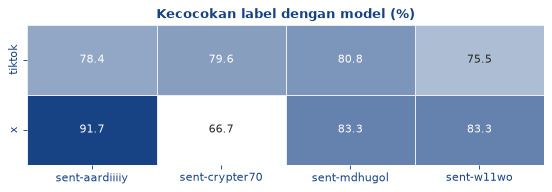

Aktif,Kondisi,Artinya,Aksi,Cara uji
,Hampir identik,Label hampir pasti buatan model itu.,"Cek aturan pretrained. Bila boleh, pakai dan sampaikan terbuka.",Cocokkan pada sampel lain.
●,Dekat,"Bisa turunan atau voting, atau preprocessing berbeda.",Coba varian preprocessing. Masukkan model itu ke blend bila diizinkan.,Teks mentah vs bersih.
,Tidak terbukti,Bukan model yang kita punya. Belum berarti label manual.,"Perlakukan label sebagai target, tetapi tetap waspada noise.",Kata pembeda per kelas.


In [21]:
cand = sorted(MODELS.glob("sent-*")) if lab is not None and len(vc) <= 6 else []
if cand:
    import torch
    from transformers import AutoModelForSequenceClassification as AMS, AutoTokenizer as ATK

    dev = "cuda" if torch.cuda.is_available() else "cpu"
    q = df.loc[lab.notna() & F.word.gt(0)]
    q = (
        q.groupby(SOURCE, group_keys=False).sample(frac=min(1, N_MODEL / len(q)), random_state=SEED)
        if has(SOURCE)
        else q.sample(min(N_MODEL, len(q)), random_state=SEED)
    )

    def predict(path, texts, bs=64):
        tk = ATK.from_pretrained(str(path), local_files_only=True)
        m = AMS.from_pretrained(str(path), local_files_only=True).eval().to(dev)
        out = []
        with torch.inference_mode():
            for i in range(0, len(texts), bs):
                e = tk(
                    texts[i : i + bs], truncation=True, max_length=128, padding=True, return_tensors="pt"
                ).to(dev)
                out.append(m(**e).logits.argmax(1).cpu().numpy())
        return np.concatenate(out)

    def agree(p, y):
        """Nama kelas model dicocokkan ke label lewat mayoritas, lalu hitung persetujuan."""
        p, y = pd.Series(p).astype(str).values, pd.Series(y).astype(str).values
        return 100 * np.mean(pd.Series(p).map(pd.crosstab(p, y).idxmax(axis=1)).values == y)

    grp_q = q[SOURCE] if has(SOURCE) else pd.Series("semua", index=q.index)
    pred = {c.name: predict(c, q[TEXT].astype(str).tolist()) for c in cand}
    fp = pd.DataFrame(
        {
            m: {g: agree(p[(grp_q == g).values], q.loc[grp_q == g, tg[0]]) for g in grp_q.unique()}
            for m, p in pred.items()
        }
    )
    heat(fp, "Kecocokan label dengan model (%)", "15_sidik", size=(7, 2.5))
    decide("y_model", fp.max().max(), "(tertinggi per sumber)")
else:
    skip("y_model")

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">16 · Pergeseran distribusi</h2>

**Pertanyaan:** random CV masih jujur? Modul ini membandingkan train vs test bila ada, kalau tidak dua sumber terbesar, kalau tidak paruh awal vs paruh akhir waktu.

In [22]:
M = "16"
from scipy.spatial.distance import jensenshannon
from scipy.stats import wasserstein_distance
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline

if test is not None:
    A, B, nama = T, test[TEXT].fillna("").astype(object), "train vs test"
elif has(SOURCE) and df[SOURCE].nunique() > 1:
    a, b = df[SOURCE].value_counts().index[:2]
    A, B, nama = T[df[SOURCE] == a], T[df[SOURCE] == b], f"{a} vs {b}"
elif has(TIME):
    A, B, nama = T[ts < ts.median()], T[ts >= ts.median()], "awal vs akhir"
else:
    A = None
if A is not None and len(B):
    a_, b_ = (
        A[A != ""].sample(min(5000, (A != "").sum()), random_state=SEED),
        B[B != ""].sample(min(5000, (B != "").sum()), random_state=SEED),
    )
    la, lb = a_.str.split().str.len(), b_.str.split().str.len()
    edges = np.unique(np.quantile(la, np.linspace(0, 1, 11)))
    edges[0], edges[-1] = -1, 1e9
    pa, pb = [np.histogram(x, edges)[0] / len(x) + 1e-4 for x in (la, lb)]
    va, vb = Counter(w for t in a_ for w in toks(t)), Counter(w for t in b_ for w in toks(t))
    xs = a_.tolist() + b_.tolist()
    yy = np.r_[np.zeros(len(a_)), np.ones(len(b_))]
    pp = cross_val_predict(
        make_pipeline(
            TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(max_iter=300)
        ),
        xs,
        yy,
        cv=3,
        method="predict_proba",
    )[:, 1]
    print(f"Perbandingan: {nama} | Wasserstein panjang {wasserstein_distance(la, lb):.2f} kata")
    decide("shift_auc", roc_auc_score(yy, pp), nama)
    decide("shift_oov", 100 * sum(c for w, c in vb.items() if w not in va) / sum(vb.values()))
    decide("shift_psi", float(((pa - pb) * np.log(pa / pb)).sum()))
else:
    skip("shift_auc", "shift_oov", "shift_psi")
kel = df[SOURCE] if has(SOURCE) else (ts >= ts.median()) if has(TIME) else None
ct = pd.crosstab(kel, lab) if lab is not None and kel is not None else pd.DataFrame()
ct = ct.loc[ct.sum(axis=1).nlargest(2).index] if len(ct) else ct
decide(
    "shift_y",
    float(jensenshannon(ct.iloc[0], ct.iloc[1])) if len(ct) == 2 else None,
    f"{ct.index[0]} vs {ct.index[1]}" if len(ct) == 2 else "",
)

Perbandingan: tiktok vs youtube | Wasserstein panjang 2.36 kata


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Mudah dibedakan,Dua kelompok jelas berbeda. Random CV bisa optimistis.,Validasi mirip kondisi test. Baca kata pembeda.,Skor lintas kelompok.
,Sedang,Ada perbedaan nyata.,Pantau per kelompok.,Skor per kelompok.
,Sulit dibedakan,Distribusi mirip.,Random atau stratified CV cukup.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Tinggi,Banyak kata baru.,"Char n-gram, embedding. Boleh fit vectorizer pada train+test bila diizinkan.",Skor kata baru.
●,Rendah,Kosakata stabil.,Word TF-IDF aman.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Besar,Panjang berbeda signifikan.,Cek MAX_LEN dan normalisasi. Bucket per panjang.,Skor per bucket.
●,Kecil,Panjang stabil.,Tidak perlu perlakuan.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Besar,"Proporsi kelas bergeser, sehingga threshold dari train bisa salah.",Decision layer bersarang. Hindari prior yang terlalu ketat.,Sebaran prediksi vs prior.
,Kecil,Proporsi stabil.,Threshold dari OOF layak.,-


<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">17 · Ablation & pola kesalahan</h2>

**Di sini hipotesis diuji.** Baseline linear pada sampel `N_ABL`, fold yang sama untuk semua varian. Baris di tabel ini berstatus *Teruji* di laporan. Hanya untuk klasifikasi satu label. Metrik memakai macro-F1, jadi ganti kalau metrik panitia berbeda.

,macro_f1,sd,selisih_vs_union
word,55.98,1.03,-5.30
char,59.73,1.07,-1.55
word + char,61.27,1.24,0.00
buang stopword,59.74,0.80,-1.53
normalisasi slang,60.86,1.59,-0.42
stemming,60.25,0.96,-1.02
buang emoji,61.10,1.26,-0.18


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Membantu,Variasi ejaan tertangkap.,Pakai word + char.,Sudah diuji di sini.
,Netral,Tidak beda di atas noise.,Pilih yang lebih murah.,Sudah diuji di sini.
,Merugikan,Char justru menambah noise.,Word saja.,Sudah diuji di sini.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Membantu,Jarang terjadi: cek apakah label berbasis kata kunci.,"Boleh dibuang, tetapi audit negasi.",Sudah diuji di sini.
,Netral,Tidak beda di atas noise.,Pertahankan: lebih sederhana.,Sudah diuji di sini.
●,Merugikan,Kata fungsi seperti negasi membawa sinyal.,Jangan buang stopword untuk klasifikasi.,Sudah diuji di sini.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Membantu,Kosakata jadi lebih rapat.,Pakai dan perluas kamus.,Sudah diuji di sini.
●,Netral,Tidak beda di atas noise.,Jangan dipakai: tambah risiko tanpa bukti.,Sudah diuji di sini.
,Merugikan,Gaya bahasa membawa sinyal.,Pakai teks mentah.,Sudah diuji di sini.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Membantu,Penyatuan kata membantu.,Pakai stem pada TF-IDF saja.,Sudah diuji di sini.
,Netral,Tidak beda di atas noise.,Lewati: biaya tanpa bukti.,Sudah diuji di sini.
●,Merugikan,Imbuhan membawa nuansa.,Jangan stem.,Sudah diuji di sini.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Membantu,Emoji menambah noise.,Boleh dibuang.,Sudah diuji di sini.
●,Netral,Tidak beda di atas noise.,Pertahankan.,Sudah diuji di sini.
,Merugikan,Emoji membawa sinyal.,Pertahankan.,Sudah diuji di sini.


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Bocor,Duplikat atau grup membuat random CV optimistis.,"Pakai group fold, kecuali test terbukti acak.",Cek binomial sampling test.
,Aman,Kebocoran grup kecil.,"Laporkan keduanya, pilih yang mirip test.",-


Aktif,Kondisi,Artinya,Aksi,Cara uji
●,Besar,Akurasi menutupi kelas kecil.,Laporkan macro-F1. Decision layer.,Argmax vs pengali.
,Kecil,Metrik seiring.,Tetap ikuti metrik resmi.,-


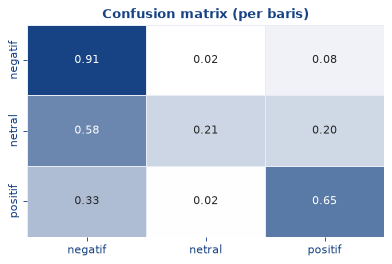

In [23]:
M = "17"
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_union
from sklearn.svm import LinearSVC

ABL = ("abl_char", "abl_stop", "abl_slang", "abl_stem", "abl_emoji", "cv_gap", "macro_gap", "err_gap")
keep = (
    lab[lab.notna() & T.ne("")].pipe(lambda c: c[c.map(c.value_counts()) >= 10])
    if lab is not None
    else pd.Series(dtype=object)
)
if keep.nunique() >= 2:
    keep = keep.groupby(keep, group_keys=False).sample(frac=min(1, N_ABL / len(keep)), random_state=SEED)
    xs, ys, cl = T[keep.index].tolist(), pd.factorize(keep, sort=True)[0], sorted(keep.unique())
    FG = list(
        StratifiedGroupKFold(3, shuffle=True, random_state=SEED).split(
            xs, ys, pd.factorize(key[keep.index])[0]
        )
    )  # teks sama tetap satu fold
    FR = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(xs, ys))

    def vec(kind):
        tf = dict(min_df=2, sublinear_tf=True, max_features=200_000)
        w, c = (
            TfidfVectorizer(ngram_range=(1, 2), **tf),
            TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), **tf),
        )
        return {"word": w, "char": c}.get(kind) or make_union(w, c)

    def run(texts, kind="union", folds=FG):
        """Kembalikan (macro-F1 per fold, prediksi OOF)."""
        sc, oof = [], np.zeros(len(ys), int)
        for a, b in folds:
            m = make_pipeline(vec(kind), LinearSVC(C=0.5)).fit([texts[i] for i in a], ys[a])
            oof[b] = m.predict([texts[i] for i in b])
            sc.append(f1_score(ys[b], oof[b], average="macro"))
        return np.array(sc), oof

    stem_map = {}
    words = lambda f: [
        re.sub(r"\b[^\W\d_]+\b", lambda m: f(m[0].lower()), x) for x in xs
    ]  # ubah per kata, emoji dan tanda baca tetap
    V = {
        "word": (xs, "word"),
        "char": (xs, "char"),
        "word + char": (xs, "union"),
        "buang stopword": (words(lambda w: "" if w in STOP else w), "union"),
        "normalisasi slang": (words(lambda w: SLANG.get(w, w)), "union"),
        "stemming": (words(lambda w: stem_map.setdefault(w, stemmer.stem(w))), "union"),
        "buang emoji": ([re.sub(EMOJI, " ", x) for x in xs], "union"),
    }
    R = {k: run(*v) for k, v in V.items()}
    base, oof = R["word + char"]
    rand_f1 = run(xs, "union", FR)[0]
    dummy = 100 * f1_score(ys, np.full(len(ys), np.bincount(ys).argmax()), average="macro")
    show(
        pd.DataFrame(
            {
                k: dict(
                    macro_f1=v[0].mean() * 100,
                    sd=v[0].std() * 100,
                    selisih_vs_union=(v[0] - base).mean() * 100,
                )
                for k, v in R.items()
            }
        ).T,
        cap=f"Ablation: {len(xs):,} baris, 3 group fold, dummy {dummy:.1f}",
    )

    gain = lambda k, ref=base: float((R[k][0] - ref).mean() * 100)
    decide("abl_char", gain("word + char", R["word"][0]), tested=True)
    for key_, name in dict(
        abl_stop="buang stopword", abl_slang="normalisasi slang", abl_stem="stemming", abl_emoji="buang emoji"
    ).items():
        decide(key_, gain(name), tested=True)
    decide(
        "cv_gap",
        float((rand_f1 - base).mean() * 100),
        f"(random {rand_f1.mean() * 100:.1f}, group {base.mean() * 100:.1f})",
        tested=True,
    )
    decide("macro_gap", 100 * (accuracy_score(ys, oof) - f1_score(ys, oof, average="macro")), tested=True)
    heat(
        pd.DataFrame(confusion_matrix(ys, oof, normalize="true"), cl, cl),
        "Confusion matrix (per baris)",
        "17_confusion",
        ".2f",
        (5, 3.4),
    )
else:
    skip(*ABL)

In [24]:
if keep.nunique() >= 2:
    tx = T[keep.index]
    B_ = {
        "panjang": pd.cut(
            tx.str.split().str.len(), [-1, 5, 15, 40, 1e9], labels=["1-5 kata", "6-15", "16-40", ">40"]
        ).astype(str),
        "negasi": tx.str.contains(FUNC["negasi"], case=False).map({True: "ada", False: "tidak"}),
        "emoji": tx.str.contains(EMOJI).map({True: "ada", False: "tidak"}),
        "bahasa": tx.map(detect).map(LANG_NAMES),
    }
    if has(SOURCE):
        B_["sumber"] = df.loc[keep.index, SOURCE].astype(str)
    rows = [
        dict(bucket=b, nilai=k, n=int(m.sum()), macro_f1=100 * f1_score(ys[m], oof[m], average="macro"))
        for b, c in B_.items()
        for k in c.unique()
        if (m := (c == k).values).sum() >= 50
    ]
    er = pd.DataFrame(rows).sort_values("macro_f1")
    show(er, 20, "Macro-F1 per subset (subset < 50 baris dibuang)")
    wrong = pd.DataFrame(
        {"teks": [clip(x) for x in xs], "benar": np.array(cl)[ys], "prediksi": np.array(cl)[oof]}
    )[ys != oof]
    show(
        wrong.sample(min(10, len(wrong)), random_state=SEED),
        cap="Contoh salah: baca, jangan hanya lihat angka",
    )
    decide(
        "err_gap",
        f1_score(ys, oof, average="macro") * 100 - er.macro_f1.min(),
        f"(terburuk: {er.iloc[0].bucket} = {er.iloc[0].nilai})",
        tested=True,
    )

,bucket,nilai,n,macro_f1
5,negasi,ada,3837,52.15
3,panjang,>40,550,54.34
2,panjang,16-40,2983,57.11
0,panjang,6-15,6594,60.51
9,sumber,tiktok,14727,61.01
7,emoji,ada,5222,61.07
6,emoji,tidak,9778,61.26
8,bahasa,Indonesia,14955,61.34
4,negasi,tidak,11163,61.59
1,panjang,1-5 kata,4873,62.82


,teks,benar,prediksi
12355,Enak kerjanya cuma lap lap ompreng ga butuh puluhan jam buat kerja tapi sehari 100rb,positif,negatif
1715,4 sehat 5 keracunan bang🗿,negatif,positif
12216,iya,positif,negatif
10710,She’s really queen🔥🔥,netral,positif
9919,modalnya ada loh orang dalem,netral,negatif
10154,gua udah 3 hari ini telur rebus😁,netral,negatif
10197,langsung to the poiny bgt ENTER 👍🏻👍🏻,netral,positif
11042,harusnya .... org dapurnya punya banyak ide u ngolah pangan lokal u jadi pangan MBG... yg,positif,negatif
13031,oh my gooodd,positif,negatif
13209,Ana sing Kacang godog plisss 😭🤣,positif,negatif


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Besar,Ada subset yang gagal. Skor rata-rata menutupinya.,Baca error subset itu. Tambah fitur atau data untuk subset itu.,F1 bucket setelah perbaikan.
●,Kecil,Performa merata.,Fokus perbaikan global.,-


<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">18 · Kelayakan komputasi</h2>

**Pertanyaan:** pendekatan mana yang muat dalam 5 jam? Waktu diukur di mesin ini lalu diskalakan linear ke `N_TARGET`. **Ukur ulang di PC panitia.**

In [25]:
M = "18"
xs18 = T[T != ""].sample(min(10000, (T != "").sum()), random_state=SEED).tolist()
w = make_union(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True),
)
t0 = time.time()
Xs = w.fit_transform(xs18)
sec_tf = (time.time() - t0) / len(xs18)
gpu = "tidak ada"
try:
    import torch

    if torch.cuda.is_available():
        gpu = f"{torch.cuda.get_device_name(0)}, {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB"
except ImportError:
    pass
show(
    pd.Series(
        {
            "GPU": gpu,
            "matriks TF-IDF": f"{Xs.shape[1]:,} fitur, {Xs.nnz / len(xs18):.0f} nnz per baris",
            "embedding per detik": round(1 / sec_embed),
            "dimensi embedding": E.shape[1],
        },
        name="nilai",
    ),
    cap="Mesin ini",
)
decide("c_tfidf", sec_tf * N_TARGET / 60, "untuk satu fit, kira-kira linear")
decide(
    "c_embed", sec_embed * N_TARGET / 60, f"(model: {EMB if (MODELS / EMB).exists() else 'cadangan TF-IDF'})"
)
decide("c_ram", E.shape[1] * 4 * N_TARGET / 1e9)

,nilai
GPU,"NVIDIA GeForce GTX 1650, 4.3 GB"
matriks TF-IDF,"64,229 fitur, 134 nnz per baris"
embedding per detik,201
dimensi embedding,384


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Lambat,Terlalu mahal untuk 5 fold.,"Pakai hashing + SGD atau word saja, 3 fold.",Ukur satu fold.
●,Layak,Baseline penuh bisa dijalankan.,Word + char penuh.,Ukur puncak RAM.


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Lambat,Tidak muat dalam 5 jam bila dicampur pekerjaan lain.,"Sampel 20-50 ribu, dedup dulu, simpan memmap.",Throughput di GPU panitia.
●,Sedang,Muat sekali. Jangan diulang.,"Embed sekali setelah dedup, simpan hasilnya.",Throughput di GPU panitia.
,Cepat,Bisa dipakai bebas.,Boleh jadi fitur.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Besar,Perlu memmap.,"Tulis ke memmap, float16 bila perlu.",Puncak RAM.
●,Aman,Muat di RAM.,Simpan .npy.,-


<div style="background:#174384;color:#fcd12a;padding:10px 16px;font-size:20px;font-weight:700;border-radius:3px;margin-top:14px">Lapis D · Kondisional</div>

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">19 · Outlier</h2>

**Pertanyaan:** ada teks ekstrem yang merusak vocabulary atau MAX_LEN? Baca dulu sebelum membuang.

In [26]:
M = "19"
mw = T.str.count(r"[^\W\d_]") / F.char.clip(lower=1)
ext = (F.word > F.word.quantile(0.999)) | (T.str.contains(r"(.)\1{9,}")) | ((F.char >= 20) & (mw < 0.5))
far = np.argsort(np.sort(sim, axis=1)[:, -5:].mean(1))[:5]
print("Semantik terjauh dari tetangganya:", *[clip(u[i]) for i in far], sep="\n  - ")
print(
    "Contoh teks ekstrem:", *T[ext].sample(min(6, int(ext.sum())), random_state=SEED).map(clip), sep="\n  - "
)
decide("outlier", pct(ext))

Semantik terjauh dari tetangganya:
  - i know baddie when i see one
  - إذا كان المحتوى هو قوتك، فماذا تكون بدونه؟
  - Siap suplay Bandeng Presto untuk kebutuhan Dapur MBG isi 2-3-4-5/Kotak (bisa request) Harg
  - Tolong dong survei, tenaga kerja yang teserap laki laki atau perempuan yang lebih banyak, 
  - Foodtray 5 Sekat Bahan : stainless 304 Embos : sus304 Diameter : 28x22x6 Wa : [samaran] ki
Contoh teks ekstrem:
  - BURGERRRRRRRRRRRRRRRR , CHIKEN KATSYUUUYYYY 💃💃
  - TIDAAAAAAAAAAAKKK
  - bener bgt gua KKN PPL di salah satu sekolah di Bandar Lampung dan ketika ada anak murid ya
  - spp sih engga ya kak, gratiss? tp ada yg namanya uang pembangunan? iuran komite? beli sera
  - [samaran] [samaran]
  - UPPPPPPPPPP


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,"Spam, tempelan panjang, atau teks rusak bisa memengaruhi vocabulary.","Baca, lalu tentukan filter. Jangan hapus dari test.",Skor dengan dan tanpa.
●,Sedikit,Ekor kecil.,"Biarkan, cukup potong panjang.",-


<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">20 · Anotasi span (NER, QA)</h2>

**Pertanyaan:** format BIO konsisten, dan seimbang antartipe? Hanya berjalan bila `TAGS` diisi.

In [27]:
M = "20"
if has(TAGS):
    seqs = df[TAGS].dropna().astype(str).str.split()

    def invalid(s):
        prev, bad = "O", 0
        for t in s:
            if t.startswith("I-") and prev[2:] != t[2:]:
                bad = 1
            prev = t
        return bad

    types = Counter(t[2:] for s in seqs for t in s if t.startswith("B-"))
    lens = [sum(1 for t in s if t != "O") / max(1, sum(1 for t in s if t.startswith("B-"))) for s in seqs]
    bars(pd.Series(types).sort_values(ascending=False), "Entitas per tipe", c=GOLD)
    save("20_tipe")
    print(f"Token per entitas (rata-rata): {np.mean(lens):.2f}")
    decide("span_bad", pct(seqs.map(invalid)))
    decide("span_rare", max(types.values()) / max(1, min(types.values())))
else:
    skip("span_bad", "span_rare")

Aktif,Kondisi,Artinya,Aksi,Cara uji
,Ada kerusakan,Anotasi tidak konsisten.,repair_bio saat decode dan latih. Laporkan.,Entity F1 sebelum dan sesudah.
,Bersih,Format aman.,Langsung token classification.,-


Aktif,Kondisi,Artinya,Aksi,Cara uji
,Timpang,Tipe langka sulit dipelajari.,Gazetteer dan aturan untuk tipe langka.,F1 per tipe.
,Wajar,Tipe cukup terwakili.,Model tunggal.,F1 per tipe.


<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">21 · Relasi antar-aspek</h2>

**Pertanyaan:** satu teks membahas banyak isu? Hasilnya menentukan multikelas, multilabel, atau ABSA, sekaligus bahan peta isu di slide.

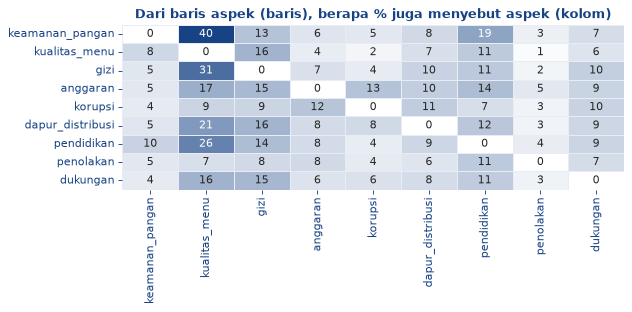

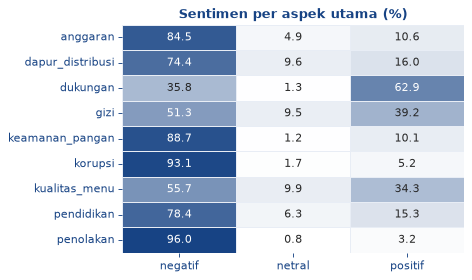

Aktif,Kondisi,Artinya,Aksi,Cara uji
,Banyak,"Satu label tidak cukup, karena aspek saling terkait.",Multi-label atau ABSA. Jangan memaksa satu kategori.,Audit 30 contoh.
●,Sedikit,Satu aspek per teks cukup sering.,Multikelas aspek layak.,Audit 30 contoh.


In [28]:
M = "21"
if DOMAIN and D.any(axis=1).any():
    A = D.to_numpy(int)
    co = (A.T @ A).astype(float)
    n = np.diag(co).copy()
    np.fill_diagonal(co, 0)
    heat(
        pd.DataFrame(co / np.maximum(n, 1)[:, None] * 100, D.columns, D.columns),
        "Dari baris aspek (baris), berapa % juga menyebut aspek (kolom)",
        "21_relasi",
        ".0f",
        (8, 4),
    )
    if lab is not None:
        heat(
            pd.crosstab(
                pd.Series(np.where(D.any(axis=1), D.values.argmax(1), -1)).map(dict(enumerate(D.columns))),
                lab.values,
                normalize="index",
            )
            * 100,
            "Sentimen per aspek utama (%)",
            "21_aspek_kelas",
            size=(6, 3.6),
        )
    decide("cooc", pct(D.sum(axis=1)[D.any(axis=1)] >= 2))
else:
    skip("cooc")

<div style="background:#174384;color:#fcd12a;padding:10px 16px;font-size:20px;font-weight:700;border-radius:3px;margin-top:14px">Laporan keputusan</div>

<h2 style="color:#174384;border-bottom:3px solid #fcd12a;padding-bottom:4px">Karakteristik data, keputusan, dan eksperimen berikutnya</h2>

Ini bagian yang dipakai untuk slide dan tanya jawab. Status **Teruji** berarti sudah dibuktikan modul 17. Status **Hipotesis** berarti masih harus diuji.

In [29]:
rep = pd.DataFrame(FIND.values()).sort_values(["modul", "id"])
aktif = rep[rep.kondisi != "Tidak berlaku"]
rep.to_csv(OUT / "keputusan.csv", index=False)
show(
    aktif[["modul", "temuan", "nilai", "kondisi", "aksi", "keputusan"]].reset_index(drop=True),
    100,
    "Matriks keputusan",
)
print(
    f"{len(aktif)} temuan aktif, {(aktif.keputusan.str.startswith('Teruji')).sum()} teruji, {len(rep) - len(aktif)} tidak berlaku. Tersimpan di {OUT / 'keputusan.csv'}"
)

,modul,temuan,nilai,kondisi,aksi,keputusan
0,01,"Relasi antarbaris (0 = tidak, 1 = ada)",1.00,"Ada id induk, grup, atau thread",Pakai group fold. Pertimbangkan konteks induk sebagai input.,"Hipotesis, uji dulu"
1,01,ID duplikat (%),40.91,ID sering berulang,Jangan menggabung atau submit berdasarkan ID sebelum dibersihkan. Selidiki pola ulangnya.,"Hipotesis, uji dulu"
2,01,Perkiraan RAM pada ukuran target (MB),102.27,Di bawah 2 GB,Pandas saja.,"Hipotesis, uji dulu"
3,02,Teks tak layak (%),5.21,Sedang,"Filter di train, tetap siapkan fallback di test.","Hipotesis, uji dulu"
4,02,Selisih teks tak layak antarsumber (poin %),5.63,Kecil,Filter global aman.,"Hipotesis, uji dulu"
5,03,Jumlah sumber,3.00,Lebih dari satu,Laporkan semua statistik per sumber. Uji model per sumber.,"Hipotesis, uji dulu"
6,03,Rasio median panjang antarsumber,2.43,Sangat berbeda,Pertimbangkan fitur sumber dan MAX_LEN dari sumber terpanjang.,"Hipotesis, uji dulu"
7,03,Jaccard kosakata terkecil antarsumber (%),20.90,Tumpang tindih kecil,Uji domain shift. Char n-gram dan embedding layak diuji.,"Hipotesis, uji dulu"
8,04,Median kata per teks,8.00,Teks pendek,Word + char n-gram sebagai baseline. Jangan buang kata.,"Hipotesis, uji dulu"
9,04,Rasio panjang p95 / p50,4.38,Sangat bervariasi,Dynamic padding dan length bucketing. Normalisasi L2 penting.,"Hipotesis, uji dulu"


69 temuan aktif, 8 teruji, 2 tidak berlaku. Tersimpan di eda_out\keputusan.csv


In [30]:
JURI = {
    "Kenapa word + char n-gram?": ["abl_char", "n_variant", "hapax", "len"],
    "Kenapa (tidak) stemming?": ["abl_stem", "stem"],
    "Kenapa (tidak) buang stopword?": ["abl_stop", "neg", "stop"],
    "Kenapa (tidak) normalisasi slang?": ["abl_slang", "n_slang"],
    "Kenapa emoji dipertahankan atau dibuang?": ["abl_emoji", "n_emoji"],
    "IndoBERTweet atau IndoBERT?": ["n_slang", "n_url", "lang_local"],
    "Perlu model multibahasa?": ["lang_local", "lang_en", "src_vocab"],
    "Berapa MAX_LEN, perlu chunking?": ["tok_cut", "len", "len_var"],
    "Kenapa macro-F1?": ["macro_gap", "y_imb"],
    "Kenapa group fold?": ["cv_gap", "dup_exact", "dup_near", "dup_cross", "unit"],
    "Random atau split waktu?": ["time_burst", "shift_auc", "cv_gap"],
    "Label bisa dipercaya?": ["y_model", "y_conflict", "y_src"],
    "HDBSCAN atau KMeans?": ["clu_big", "clu_noise", "clu_sil"],
    "Perlu embedding atau cross-encoder?": ["sem_para", "sem_clash", "pair_lex", "pair_sem"],
    "Multikelas, multilabel, atau ABSA?": ["cooc", "contrast", "y_type"],
    "Muat dalam 5 jam?": ["c_tfidf", "c_embed", "c_ram", "mem"],
}


def jawab(ks):
    tag = lambda f: "[Teruji] " if f["keputusan"].startswith("Teruji") else ""
    return (
        " ".join(
            f"{tag(f)}{f['temuan']}: {f['nilai']:,.3g} ({f['kondisi']}). {f['aksi']}"
            for f in (FIND[k] for k in ks)
            if f["nilai"] is not None
        )
        or "Belum ada bukti di data ini."
    )


qa = [
    dict(pertanyaan=q, jawaban=jawab(ks), rujukan=", ".join(FIND[k]["id"] for k in ks))
    for q, ks in JURI.items()
]
display(
    HTML(
        pd.DataFrame(qa)
        .to_html(index=False, escape=True)
        .replace("<th", f"<th style='background:{NAVY};color:#fff;text-align:left;padding:5px 8px'")
        .replace("<td", f"<td style='text-align:left;padding:5px 8px;color:{NAVY}'")
    )
)
next_up = (
    aktif[aktif.keputusan.str.startswith("Hipotesis") & ~aktif.uji.isin(["-", ""])]
    .drop_duplicates("uji")[["id", "kondisi", "uji"]]
    .rename(columns={"uji": "eksperimen berikutnya"})
)
show(next_up.reset_index(drop=True), 40, "Eksperimen yang masih perlu dijalankan")
(OUT / "laporan.md").write_text(
    "# Laporan EDA\n\n" + "\n".join(f"## {q['pertanyaan']}\n{q['jawaban']}\n" for q in qa), encoding="utf-8"
)
print("Laporan:", OUT / "laporan.md", "| Grafik:", len(list(OUT.glob("*.png"))), "file di", OUT)

pertanyaan,jawaban,rujukan
Kenapa word + char n-gram?,[Teruji] Efek char n-gram terhadap word (poin macro-F1): 5.3 (Membantu). Pakai word + char. Kata langka mirip kata umum (%): 8.2 (Rendah). Word n-gram cukup sebagai awal. Kata muncul sekali (% tipe): 44.4 (Wajar). Word TF-IDF sudah kuat. Median kata per teks: 8 (Teks pendek). Word + char n-gram sebagai baseline. Jangan buang kata.,"EDA-57, EDA-23, EDA-24, EDA-09"
Kenapa (tidak) stemming?,[Teruji] Efek stemming (poin macro-F1): -1.02 (Merugikan). Jangan stem. Pengurangan tipe kata setelah stemming (%): 20.5 (Besar). Uji stem pada word TF-IDF. Jangan untuk transformer.,"EDA-60, EDA-25"
Kenapa (tidak) buang stopword?,[Teruji] Efek buang stopword (poin macro-F1): -1.53 (Merugikan). Jangan buang stopword untuk klasifikasi. Teks memuat negasi (%): 24.3 (Banyak). Jangan buang stopword secara agresif. Pertahankan bigram dan negasi. Token stopword (%): 18.9 (Kecil). Tidak perlu membuang stopword.,"EDA-58, EDA-28, EDA-27"
Kenapa (tidak) normalisasi slang?,[Teruji] Efek normalisasi slang (poin macro-F1): -0.416 (Netral). Jangan dipakai: tambah risiko tanpa bukti. Teks memuat slang (%): 41.6 (Banyak). Uji varian mentah vs normalisasi. Model teks sosial (IndoBERTweet) layak jadi kandidat utama.,"EDA-59, EDA-17"
Kenapa emoji dipertahankan atau dibuang?,[Teruji] Efek buang emoji (poin macro-F1): -0.178 (Netral). Pertahankan. Teks memuat emoji (%): 35.7 (Banyak). Pertahankan atau ubah jadi kata. Pastikan tokenizer tidak membuangnya.,"EDA-61, EDA-18"
IndoBERTweet atau IndoBERT?,"Teks memuat slang (%): 41.6 (Banyak). Uji varian mentah vs normalisasi. Model teks sosial (IndoBERTweet) layak jadi kandidat utama. Teks memuat URL atau mention (%): 3.27 (Sedikit). Ganti dengan penanda, tanpa uji khusus. Bahasa daerah, batas ketat (%): 0.17 (Sangat kecil). Tidak perlu model multibahasa.","EDA-17, EDA-22, EDA-15"
Perlu model multibahasa?,"Bahasa daerah, batas ketat (%): 0.17 (Sangat kecil). Tidak perlu model multibahasa. Teks dominan Inggris (%): 0.07 (Sedikit). Model Indonesia cukup. Jaccard kosakata terkecil antarsumber (%): 20.9 (Tumpang tindih kecil). Uji domain shift. Char n-gram dan embedding layak diuji.","EDA-15, EDA-16, EDA-08"
"Berapa MAX_LEN, perlu chunking?",Teks melewati 128 token (%): 0.36 (Hampir tidak ada). Pakai p99 token sebagai MAX_LEN. Median kata per teks: 8 (Teks pendek). Word + char n-gram sebagai baseline. Jangan buang kata. Rasio panjang p95 / p50: 4.38 (Sangat bervariasi). Dynamic padding dan length bucketing. Normalisasi L2 penting.,"EDA-11, EDA-09, EDA-10"
Kenapa macro-F1?,[Teruji] Akurasi minus macro-F1 (poin): 17 (Besar). Laporkan macro-F1. Decision layer. Rasio kelas terbesar / terkecil: 8.3 (Timpang). Macro-F1 dan pengali per kelas pada OOF.,"EDA-64, EDA-49"
Kenapa group fold?,"[Teruji] Random fold minus group fold (poin macro-F1): 7.49 (Bocor). Pakai group fold, kecuali test terbukti acak. Duplikat persis (%): 40.3 (Banyak). Group fold berdasarkan teks. Laporkan volume asli vs copypasta. Baris dalam grup near-duplicate (%): 0.4 (Sedikit). Grup exact cukup. Teks muncul di lebih dari satu grup atau sumber (% unik berulang): 0.57 (Sedikit). Group fold biasa. Relasi antarbaris (0 = tidak, 1 = ada): 1 (Ada id induk, grup, atau thread). Pakai group fold. Pertimbangkan konteks induk sebagai input.","EDA-62, EDA-40, EDA-42, EDA-43, EDA-01"


,id,kondisi,eksperimen berikutnya
0,EDA-01,"Ada id induk, grup, atau thread",Bandingkan skor random fold dan group fold (modul 17).
1,EDA-02,ID sering berulang,Bandingkan isi baris ber-ID sama.
2,EDA-04,Sedang,Lihat 30 contoh sebelum membuang.
3,EDA-06,Lebih dari satu,Leave-one-source-out (modul 16).
4,EDA-07,Sangat berbeda,Skor per sumber dengan fitur yang sama.
5,EDA-08,Tumpang tindih kecil,"Latih di satu sumber, uji di sumber lain."
6,EDA-09,Teks pendek,"Ablation word, char, union (modul 17)."
7,EDA-10,Sangat bervariasi,Skor per bucket panjang.
8,EDA-11,Hampir tidak ada,Throughput sebelum dan sesudah.
9,EDA-12,Sedikit,Bandingkan rentang train dan test.


Laporan: eda_out\laporan.md | Grafik: 24 file di eda_out
